# AKE Lab 3 · Sequenzmodelle & Transformer — Musterlösung

**Angewandte KI & KI-Engineering · Block A – Vertiefung Deep Learning · Woche 3**
Skript: *Sequenzmodelle & Transformer*, Abschn. 2–3 und 5–7 · Dieses Notebook enthält alles, was Sie für das Lab brauchen.

Musterlösung mit Ausgaben. Die Zahlen stammen aus dem Lauf, mit dem dieses Notebook erzeugt wurde (`torch.manual_seed(0)` vor jedem Modell); auf anderer Hardware weichen Laufzeiten und letzte Nachkommastellen ab, die qualitativen Aussagen nicht.


**Referenzlauf dieser Musterlösung:** Apple M4 Pro (14 Kerne), 48 GB RAM, PyTorch 2.8.0 (CPU), auf **4 Threads** begrenzt
(`torch.set_num_threads(4)`, `OMP_NUM_THREADS=4`), keine GPU/MPS. Reine Rechenzeit laut Zelle *Laufzeiten* am Ende:

| Teil | gemessen (4 Threads, M4 Pro) | Schätzung Referenz-Laptop (4 Kerne, Faktor ≈ 2–4) |
|---|---|---|
| Aufgaben 0–4 (Tokenisierung, Embeddings, Attention, Stufe 1) | 4 s | ≈ 10–20 s |
| Aufgabe 5 (Laden, Fine-Tuning 125 Schritte 43 s, Testauswertung) | 52 s | ≈ 1,5–3,5 Min. |
| Aufgabe 6 (Latenzmessung, BERT-base mit zufälligen Gewichten) | 5 s | ≈ 10–20 s |
| **Pflichtteil gesamt** | **1,0 Min.** | **≈ 2–4 Min.** (Budget 8 Min., Fine-Tuning ≤ 5 Min.) |
| Optional O1–O4 (davon UMAP 2 × ≈ 5 s) | 13 s | ≈ 30–50 s |

Faktor 2 ist die Lab-2-Konvention (ein M4-Pro-Leistungskern ist etwa doppelt so schnell wie ein typischer Laptop-Kern), Faktor 4
die vorsichtige Obergrenze. Beide sind geschätzt, nicht gemessen. Latenzen schwanken auf demselben Rechner zwischen Läufen um bis zu
Faktor 2–3 (Hintergrundlast); Reihenfolge und Verhältnisse der Modelle bleiben stabil.


**Rechenbudget (Referenz 4 Kerne / 8 GB, keine GPU):** reine Rechenzeit ≈ 2–4 Min. – das Fine-Tuning in 5.2 dauert ≈ 1,5–3 Min.,
alles andere Sekunden. Der Abschnitt *Optional* gehört nicht zum Budget. Die Zelle **Laufzeiten** am Ende zeigt Ihre eigene Rechenzeit.

**Vorab, einmalig (mit Internet):** `setup_check.ipynb` in diesem Ordner ausführen. Es legt die DistilBERT-Gewichte (268 MB) nach
`data/models/distilbert-base-uncased/`. Das Lab selbst arbeitet **offline** (`HF_HUB_OFFLINE=1`) und lädt nichts nach.

**Fallback:** Jedes Experiment schreibt ein JSON-Log nach `results/`. Dauert ein Lauf zu lange oder bricht er ab, laden Sie das passende
Referenzlog mit `lade_referenz("a5_finetune")` aus `results_referenz/`, bearbeiten die Interpretation trotzdem und kennzeichnen das im Notebook.

**Arbeitsarten** (stehen am Anfang jeder Aufgabe): `CODE` wenige Zeilen ergänzen · `AUSFÜHREN` vorgegebene Zelle ausführen ·
`PAPIER` erst von Hand rechnen · `DENKEN` Leitfrage beantworten (Stichpunkte genügen)

**So arbeiten Sie**
- Zellen der Reihe nach mit *Shift + Enter* ausführen. Nach einem Kernel-Neustart alles von oben erneut ausführen.
- Zu ergänzen ist nur, was mit `# TODO x.y` markiert ist: Die Zeile `raise NotImplementedError("TODO x.y")` durch Ihren Code ersetzen.
  Jede TODO-Lücke braucht 1–8 Zeilen; der Tipp im Kommentar darüber nennt die passenden Funktionen.
- Direkt nach jeder TODO-Zelle folgt eine **Prüfzelle**: ✅ heißt richtig, ❌ nennt einen Hinweis. Erst weiter, wenn alles ✅ ist.
- Fehlermeldungen von **unten** lesen: Die letzte Zeile nennt den Fehler, darüber steht die betroffene Codezeile.

## Organisatorisches

| | |
|---|---|
| **Termin** | KW 43 (22.10.2026), 2-SWS-Lab-Block im Anschluss an den 4-SWS-Theorieblock; 90 Min. Präsenz |
| **Skript-Bezug** | *Sequenzmodelle & Transformer*: Abschn. 2–3 (Tokenisierung, Embeddings), 5–6 (Attention, Transformer), 7 (Vortraining und Fine-Tuning), 8 (Analyse, nur Optional); Trainingsschleife aus *Vom Perzeptron zum Deep Network* (Lab) |
| **Material** | Ordner `lab03/` im Kursrepository: dieses Notebook, `setup_check.ipynb`, `results_referenz/` (Referenzlogs des Lösungslaufs, Fallback), `referenz/` (BERT-base-Literaturwerte); die Musterlösung wird nach der Sitzung freigeschaltet |
| **Umgebung** | Kursumgebung aus dem ersten Lab (`git pull`, danach `uv sync`); es wird nichts neu installiert. **Vorab mit Internet:** `setup_check.ipynb` lädt einmalig die DistilBERT-Gewichte (268 MB); im Lab selbst kein Hub-Zugriff |
| **Daten** | Unter `data/`: `imdb/` (IMDB-Teilmenge, 5 000 Trainings-/1 000 Testrezensionen, je zur Hälfte positiv), `cache/emb_minilm.npy` (Referenz-Cache der MiniLM-Embeddings aller 6 000 Texte, 9 MB), `models/` (`all-MiniLM-L6-v2`, 91 MB; GPT-2-Tokenizer; DistilBERT-Konfiguration und -Tokenizer, nach dem Setup-Check auch die Gewichte) |
| **Capstone** | Das Trägermodell ruht diese Woche; die Modelle dieses Labs werden nicht weiterverwendet. Die Themenvorstellung für das Capstone folgt in Woche 4. |

**Zeitplan (verteilt über die Vorlesung)**

Das Lab läuft nicht als Block am Ende, sondern in acht Abschnitten direkt nach dem passenden Vorlesungsteil. Ein Teil wird
**live gemeinsam** programmiert (der Dozent tippt am Beamer vor, Sie tippen mit), einen Teil bearbeiten Sie **allein**. Am Ende
jedes Blocks wird die Lösung gezeigt und die Interpretation gemeinsam besprochen. Nicht fertig? Fehlende Zeilen aus der Lösung
übernehmen – die Aufgaben bauen aufeinander auf.

| Block | im Anschluss an (Vorlesung) | allein | live gemeinsam | Besprechung | Rechenzeit (4 Kerne) |
|---|---|---|---|---|---|
| 0 · Setup | Einstieg | 5 Min. | – | – | Sekunden |
| 1 · Tokenisierung | Tokenisierung | 13 Min. (1.1 Papier, 1.1a, 1.2) | 5 Min. (1.1b) | 4 Min. | Sekunden |
| 2 · Embeddings und Ähnlichkeit | Embeddings | 7 Min. (2.1–2.3) | – | 3 Min. | Sekunden |
| 3.1–3.4 · Self-Attention von Hand | Attention | 14 Min. (3.1, Papier 3.2, 3.3, 3.4) | 6 Min. (3.2) | 3 Min. | Sekunden |
| 3.5 · Permutationstest und Positionskodierung | Positionskodierung | 4 Min. | – | 2 Min. | Sekunden |
| 4 · Stufe 1: Embeddings + logistische Regression | Eingefroren oder feinjustiert? | 4 Min. (4.2) | 6 Min. (4.1) | 3 Min. | Sekunden |
| 5 · Stufe 2: DistilBERT feinjustieren | Destillation: DistilBERT | 4 Min. (5.3) | 6 Min. (5.1, 5.2) | 5 Min. | ≈ 1,5–3 Min. |
| 6 · Modellgröße bewerten | Zwischenstand Vortraining | 3 Min. (6.1) | 2 Min. (6.2 gezeigt) | 4 Min. | ≈ 10–20 s |
| danach | Optional O1–O4 (Selbststudium) | | | | ≈ 1 Min. |

Summe 103 Min.: 54 Min. allein, 49 Min. gemeinsam. Reine Rechenzeit des Pflichtteils ≈ 2–4 Min.
Lassen Sie das Notebook über die ganze Sitzung geöffnet – nach einem Kernel-Neustart müssen alle Zellen von oben neu laufen.
„Lernziel“ und „Intuition“ am Anfang jeder Aufgabe wiederholen die Vorlesung und können übersprungen werden.
Die Interpretationsfragen beantworten wir gemeinsam in der Besprechung; schreiben Sie Stichpunkte unter **Ihre Antwort** mit.

## Spielregeln und Hinweise

> **In der Praxis: Teures einmal rechnen, dann cachen.** Ein eingefrorener Encoder liefert für denselben Text immer denselben Vektor.
> Embeddings einmal berechnen und als `.npy` ablegen; danach kostet jedes Experiment mit dem Kopf Sekunden (Aufgabe 4).
> **Offline arbeiten:** `HF_HUB_OFFLINE=1` muss gesetzt sein, *bevor* `transformers` importiert wird – sonst versucht die Bibliothek beim
> Laden, den Hub zu erreichen. Modelle immer aus dem lokalen Ordner laden, Tokenizer und Modell aus demselben Ordner.

- **Reproduzierbarkeit:** `torch.manual_seed(0)` vor jedem Modell; jedes Experiment schreibt sein JSON-Log nach `results/`.
  Zeitmessungen mit `torch.set_num_threads(min(4, os.cpu_count()))` (erledigt die Setup-Zelle).
- **Evaluation:** immer mit `model.eval()` und `torch.inference_mode()`. Die IMDB-Testmenge wird **je Modell genau einmal** ausgewertet;
  $C$ wird per Kreuzvalidierung gewählt, nicht auf dem Test. Die Lernkurve in 4.2 ist eine Diagnose, keine Modellauswahl.
- **Fallback auf Referenzlogs:** Dauert das Fine-Tuning zu lange oder bricht es ab, laden Sie das Log mit `lade_referenz("a5_finetune")`
  aus `results_referenz/` (es enthält auch die Testwahrscheinlichkeiten) und bearbeiten die Interpretation damit; markieren Sie das im
  Notebook. Auf sehr langsamen Rechnern friert `FREEZE = 3` in 5.2 die unteren drei Schichten ein.
- **Offline-Fehler:** `OSError: ... not found` oder `LocalEntryNotFoundError` heißen im Offline-Modus: Eine Datei unter `data/models/`
  fehlt oder der Pfad stimmt nicht. Erst `git pull` und `setup_check.ipynb`, dann die Setup-Zelle erneut (Skript Tab. 7).
- **Erwartungswerte** in den Aufgaben stammen aus dem Lösungslauf (Seed 0, 4 Threads). Genauigkeiten sollten Sie auf etwa einen
  Prozentpunkt treffen; Zeiten und Latenzen hängen von Ihrem Rechner ab.

## Aufgabe 0 · Setup

`AUSFÜHREN` · ≈ 5 Min., Pflicht, ohne Abgabe

1. **Vorab (mit Internet):** im Ordner des Repositorys `git pull` und `uv sync`, dann `lab03/setup_check.ipynb` einmal ausführen
   (Download 268 MB, alle Prüfungen ✅).
2. Im Ordner des Repositorys `uv run jupyter notebook` starten, dieses Starter-Notebook als `lab03_<nachname>.ipynb` kopieren und nur in
   der Kopie arbeiten.
3. Die beiden folgenden Zellen ausführen.

Die Setup-Zelle schaltet zuerst den Hub-Zugriff ab (`HF_HUB_OFFLINE=1`, `TRANSFORMERS_OFFLINE=1` – das muss **vor**
dem Import von `transformers` geschehen), begrenzt PyTorch auf höchstens 4 Threads (vergleichbare Zeitmessungen), sucht das
Kursrepository (erster Elternordner mit `pyproject.toml`) und prüft die Daten unter `data/`: IMDB-Teilmenge (5 000 Trainings-,
1 000 Testrezensionen), Referenz-Cache der MiniLM-Embeddings, MiniLM, GPT-2-Tokenizer und DistilBERT. Sie legt `results/` und
`cache/` (hier in `lab03/`) an. **Erwartung:** alle Prüfungen ✅. Fehlen nur die DistilBERT-Gewichte, zuerst `setup_check.ipynb` ausführen.

In [1]:
# --- Offline-Modus: MUSS vor dem Import von transformers / sentence_transformers stehen ---------------------
import os
os.environ["HF_HUB_OFFLINE"] = "1"                       # kein Hub-Zugriff: alle Modelle liegen in data/models/
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")  # keine Warnungen der Rust-Tokenizer

# --- Bibliotheken -------------------------------------------------------------------------------------
import sys, time, json, math, copy, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix
warnings.filterwarnings("ignore", message="IProgress not found")       # tqdm ohne ipywidgets
warnings.filterwarnings("ignore", message=r".*encountered in matmul", category=RuntimeWarning)  # Scheinwarnung von NumPy 2
                                                       # mit Apple Accelerate (macOS); die Ergebnisse sind korrekt
import huggingface_hub, transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sentence_transformers import SentenceTransformer
transformers.utils.logging.disable_progress_bar()

torch.set_num_threads(min(4, os.cpu_count()))           # Referenz: 4 Kerne (Skript, Listing 6 Latenzmessung)
torch.manual_seed(0); np.random.seed(0)
DEVICE = torch.device("cpu")                            # das ganze Lab ist fuer die CPU ausgelegt

# --- Pruefhelfer: gibt ✅ oder ❌ mit Hinweis aus, statt mit einem nackten assert abzubrechen ---------------
CHECKS = {}
def check(name, ok, hint=""):
    """ok: Wahrheitswert oder Funktion ohne Argumente (Fehler darin -> ❌ mit Fehlermeldung)."""
    try:
        ok = bool(ok() if callable(ok) else ok)
        msg = hint
    except NotImplementedError as e:
        ok, msg = False, f"{e} ist noch offen"
    except Exception as e:
        ok, msg = False, f"{type(e).__name__}: {e}" + (f" | {hint}" if hint else "")
    CHECKS[name] = ok
    print(f"✅ {name}" if ok else f"❌ {name} – Hinweis: {msg}")

# --- Laufzeitmessung: reine Rechenzeit aller Zellen, je Aufgabe aufsummiert (Tabelle am Ende des Notebooks) ---
RUNTIME, _teil = {}, {"name": "Aufgabe 0", "t0": None}
def abschnitt(name):
    """Ab jetzt zaehlt die Rechenzeit fuer `name`."""
    _teil["name"] = name
def _ake_pre(*args):
    _teil["t0"] = time.perf_counter()
def _ake_post(*args):
    if _teil["t0"] is not None:
        RUNTIME[_teil["name"]] = RUNTIME.get(_teil["name"], 0.0) + time.perf_counter() - _teil["t0"]
try:
    _ip = get_ipython()
    for ev, fn in (("pre_run_cell", _ake_pre), ("post_run_cell", _ake_post)):
        for old in [f for f in _ip.events.callbacks[ev] if getattr(f, "__name__", "") == fn.__name__]:
            _ip.events.unregister(ev, old)                  # bei erneutem Ausfuehren nicht doppelt zaehlen
        _ip.events.register(ev, fn)
except NameError:
    pass                                                    # ausserhalb von Jupyter: keine Messung

# --- Pfade: REPO_ROOT = erster Elternordner mit pyproject.toml ----------------------------------------------
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Kein Kursrepository gefunden (kein Ordner mit pyproject.toml oberhalb von "
                            f"{Path.cwd()}). Bitte Jupyter im Ordner des Repositorys starten und lab03/ oeffnen.")
DATA      = REPO_ROOT / "data"
RESULTS   = Path("results")                      # JSON-Logs je Experiment (relativ zu lab03/)
CACHE     = Path("cache")                        # eigene Zwischenergebnisse (relativ zu lab03/)
IMDB      = DATA / "imdb"
MINILM    = DATA / "models" / "all-MiniLM-L6-v2"          # Sentence-Transformer, 22,7 Mio. Parameter
DBERT     = DATA / "models" / "distilbert-base-uncased"   # 66 Mio. Parameter; Gewichte per setup_check.ipynb
GPT2TOK   = DATA / "models" / "gpt2-tokenizer"            # nur der Tokenizer (Byte-Level-BPE)
EMB_CACHE = DATA / "cache" / "emb_minilm.npy"             # Referenz-Cache: MiniLM-Embeddings aller 6 000 Texte
REFERENZ  = Path("referenz") / "erweitertes_lab_referenz.json"   # BERT-base-Zeile fuer Aufgabe 6

print(f"torch {torch.__version__} | transformers {transformers.__version__} | Geraet: {DEVICE} | "
      f"Threads: {torch.get_num_threads()} | CPU-Kerne: {os.cpu_count()}")
print(f"REPO_ROOT: {REPO_ROOT}\n")

# --- Pruefungen -------------------------------------------------------------------------------------------
check("Hub-Zugriff abgeschaltet (HF_HUB_OFFLINE=1 vor dem Import gesetzt)", huggingface_hub.constants.HF_HUB_OFFLINE,
      "Kernel neu starten und diese Zelle als ERSTE ausfuehren")
n_tr = len(pd.read_parquet(IMDB / "imdb_train.parquet", columns=["label"])) if (IMDB / "imdb_train.parquet").exists() else 0
n_te = len(pd.read_parquet(IMDB / "imdb_test.parquet", columns=["label"])) if (IMDB / "imdb_test.parquet").exists() else 0
check(f"IMDB-Teilmenge: {n_tr} Train / {n_te} Test", (n_tr, n_te) == (5000, 1000), "data/imdb/ fehlt -> im Repository git pull")
check("Referenz-Cache data/cache/emb_minilm.npy (6 000 x 384)",
      lambda: np.load(EMB_CACHE, mmap_mode="r").shape == (6000, 384), "Datei fehlt -> git pull")
check("MiniLM in data/models/all-MiniLM-L6-v2",
      all((MINILM / f).exists() for f in ["model.safetensors", "modules.json", "1_Pooling/config.json", "tokenizer.json"]),
      "Ordner unvollstaendig -> git pull")
check("GPT-2-Tokenizer in data/models/gpt2-tokenizer", (GPT2TOK / "tokenizer.json").exists(), "git pull")
check("DistilBERT-Konfiguration und -Tokenizer", all((DBERT / f).exists() for f in ["config.json", "tokenizer.json"]), "git pull")
for d in (RESULTS, CACHE):
    d.mkdir(exist_ok=True)
check("Ordner results/ und cache/ angelegt", RESULTS.is_dir() and CACHE.is_dir())
if not all(CHECKS.values()):
    raise FileNotFoundError("Daten unvollstaendig (siehe ❌ oben). Im Repository 'git pull' ausfuehren und "
                            "die Setup-Zelle erneut starten.")
# Die Gewichte braucht erst Aufgabe 5; fehlen sie, laufen die Aufgaben 1-4 trotzdem.
DBERT_OK = (DBERT / "model.safetensors").exists()
check("DistilBERT-Gewichte data/models/distilbert-base-uncased/model.safetensors (fuer Aufgabe 5)", DBERT_OK,
      "fehlen -> einmal setup_check.ipynb ausfuehren (Download 268 MB) oder die Datei vom Hochschul-Share dorthin kopieren")

torch 2.8.0 | transformers 4.57.6 | Geraet: cpu | Threads: 4 | CPU-Kerne: 14
REPO_ROOT: /Users/stefan/Documents/02_PHWT/DS-Vorlesung/03_Git_Studierende

✅ Hub-Zugriff abgeschaltet (HF_HUB_OFFLINE=1 vor dem Import gesetzt)
✅ IMDB-Teilmenge: 5000 Train / 1000 Test
✅ Referenz-Cache data/cache/emb_minilm.npy (6 000 x 384)
✅ MiniLM in data/models/all-MiniLM-L6-v2
✅ GPT-2-Tokenizer in data/models/gpt2-tokenizer
✅ DistilBERT-Konfiguration und -Tokenizer
✅ Ordner results/ und cache/ angelegt
✅ DistilBERT-Gewichte data/models/distilbert-base-uncased/model.safetensors (fuer Aufgabe 5)


In [2]:
# --- IMDB-Teilmenge: 5 000 Trainings- und 1 000 Testrezensionen, je zur Haelfte positiv (label 1) / negativ (0) ---
train_df = pd.read_parquet(IMDB / "imdb_train.parquet")
test_df  = pd.read_parquet(IMDB / "imdb_test.parquet")
texts_tr, y_tr = train_df.text.tolist(), train_df.label.to_numpy()
texts_te, y_te = test_df.text.tolist(),  test_df.label.to_numpy()
print(f"Train {len(texts_tr)} (positiv {y_tr.mean():.1%}) | Test {len(texts_te)} (positiv {y_te.mean():.1%}) | "
      f"erste 1 000 Train: positiv {y_tr[:1000].mean():.1%}")
for lab, name in [(1, "positiv"), (0, "negativ")]:
    i = int(np.argmax(y_tr == lab))
    print(f"\nBeispiel {name} (Train #{i}, {len(texts_tr[i].split())} Woerter):\n  "
          + texts_tr[i][:400].replace("<br />", " ") + " ...")

Train 5000 (positiv 50.0%) | Test 1000 (positiv 50.0%) | erste 1 000 Train: positiv 48.1%

Beispiel positiv (Train #0, 58 Woerter):
  I so much enjoyed this little musical fantasy I bought a copy to share with my friends. It is a pleasant and diverting change from our mundane lives..... I believe that we can all benefit from an active fantasy life, one of joy and indulgence, I heartily recommend it!  The performance is excellent, and the music uplifting! ...

Beispiel negativ (Train #1, 528 Woerter):
  Congratulations to Christina Ricci for making this movie and putting her mojo behind this important subject and trying to make a great film. Ricci is my favorite actress: She is so gifted, so natural, her reactions are perfect and so is the energy she constantly radiates, which gives credence to the often misapplied term "star."   The film misses its mark for lots of various reasons, but ...


### Werkzeuge aus Lab 1 (unverändert) und neue Helfer

`run_epoch`, `fit` und `plot_history` sind **unverändert** aus Lab 1 übernommen: Die Schleife kennt keine Architektur, nur `model(x)`.
Neu ist nur ein **Adapter** für Hugging-Face-Modelle: `text_loader` liefert je Batch ein Dict aus der Tokenizer-Ausgabe
(`input_ids`, `attention_mask`, dynamisch auf die längste Sequenz im Batch aufgefüllt), und `HFClassifier` macht daraus
`model(x) -> Logits`, genau die Schnittstelle, die `fit` erwartet. Dazu `predict` (Testvorhersage mit `model.eval()` und
`torch.inference_mode()`), `save_log`/`lade_referenz` und eine Heatmap-Funktion.

In [3]:
lossf = nn.CrossEntropyLoss()   # erwartet Logits, kein Softmax davor!

def run_epoch(model, loader, opt=None):
    """Eine Epoche. opt=None => reine Evaluation (kein Gradient, eval()-Modus)."""
    train_mode = opt is not None
    model.train(train_mode)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            logits = model(x)
            loss = lossf(logits, y)
            if train_mode:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y)
            correct  += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, correct / n

def fit(model, opt, loaders, epochs, name=None, patience=None, verbose=True):
    """Trainiert `epochs` Epochen, loggt Train-/Val-Verlust und -Genauigkeit.
    patience=k: Early Stopping — Abbruch nach k Epochen ohne Verbesserung des Val-Verlusts,
    beste Parameter werden wiederhergestellt. Rueckgabe: history-Dict (auch als JSON in results/)."""
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_loss, best_state, bad = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = run_epoch(model, loaders["train"], opt)
        va = run_epoch(model, loaders["val"])
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], (*tr, *va)):
            hist[k].append(v)
        hist["epoch_time"].append(time.time() - t0)
        if verbose:
            print(f"  Epoche {ep:3d}: train loss {tr[0]:.4f} acc {tr[1]:.2%} | "
                  f"val loss {va[0]:.4f} acc {va[1]:.2%} | {hist['epoch_time'][-1]:.1f}s")
        if not math.isfinite(va[0]):
            print("  -> Verlust nicht endlich, Abbruch."); break
        if va[0] < best_loss:
            best_loss, bad = va[0], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience is not None and bad >= patience:
                print(f"  -> Early Stopping nach Epoche {ep} (bestes Val-Loss {best_loss:.4f} "
                      f"in Epoche {ep - bad}).")
                break
    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)          # Parameterstand am Val-Minimum behalten
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1
    if name:
        (RESULTS / f"{name}.json").write_text(json.dumps(hist, indent=1))
    return hist

def plot_history(hists, title="", metric="loss", ax=None, logy=False):
    """hists: {label: history}. Zeichnet Train (durchgezogen) und Val (gestrichelt)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.6))
    for i, (label, h) in enumerate(hists.items()):
        c = f"C{i}"
        ax.plot(range(1, len(h[f"train_{metric}"]) + 1), h[f"train_{metric}"], c, label=f"{label} (train)")
        ax.plot(range(1, len(h[f"val_{metric}"]) + 1),   h[f"val_{metric}"],   c + "--", label=f"{label} (val)")
    ax.set_xlabel("Epoche"); ax.set_ylabel(metric); ax.set_title(title); ax.grid(alpha=.3)
    if logy: ax.set_yscale("log")
    ax.legend(fontsize=7)
    return ax

# ---------------------------------------------------------------- Helfer aus Lab 2
def save_log(name, hist=None, **extra):
    """JSON-Log in results/: Seed, Konfiguration, Kurven, Laufzeit (Debug-Protokoll: jeden Lauf loggen)."""
    conv = lambda o: o.tolist() if hasattr(o, "tolist") else float(o)
    log = {"seed": 0, "torch": torch.__version__, "threads": torch.get_num_threads(), **(hist or {}), **extra}
    (RESULTS / f"{name}.json").write_text(json.dumps(log, indent=1, ensure_ascii=False, default=conv))
    return log

def lade_referenz(name):
    """Fallback: mitgeliefertes Referenzlog aus results_referenz/<name>.json als Dict."""
    return json.loads((Path("results_referenz") / f"{name}.json").read_text())

# ---------------------------------------------------------------- neu in diesem Lab: Adapter fuer Hugging Face
class HFClassifier(nn.Module):
    """Adapter: Hugging-Face-Klassifikator -> Modul, das wie in Lab 1 Logits zurueckgibt (model(x) mit x = Dict)."""
    def __init__(self, hf_model):
        super().__init__(); self.hf = hf_model
    def forward(self, x):
        return self.hf(**x).logits

def text_loader(tok, texts, labels, max_length=128, batch_size=16, shuffle=False):
    """Loader fuer (Tokenizer-Ausgabe, Label); tokenisiert je Batch mit dynamischem Padding und Truncation."""
    def collate(batch):
        t, y = zip(*batch)
        enc = tok(list(t), truncation=True, max_length=max_length, padding=True, return_tensors="pt")
        enc.pop("token_type_ids", None)
        return dict(enc), torch.tensor(y)
    return DataLoader(list(zip(texts, labels)), batch_size=batch_size, shuffle=shuffle, collate_fn=collate)

def predict(model, loader):
    """P(positiv) fuer alle Beispiele des Loaders -- model.eval() + torch.inference_mode() (kein Dropout, kein Gradient)."""
    model.eval()
    with torch.inference_mode():
        return torch.cat([model(x).softmax(-1)[:, 1] for x, _ in loader]).numpy()

def heatmap(M, xlabels, ylabels=None, title="", ax=None, fmt="{:.2f}", cmap="Blues", vmin=None, vmax=None):
    """Matrix mit Zahlen in jeder Zelle (Attention-Gewichte, Kosinusmatrix, Konfusionsmatrix)."""
    M = np.asarray(M); ylabels = xlabels if ylabels is None else ylabels
    if ax is None:
        _, ax = plt.subplots(figsize=(0.75 * M.shape[1] + 1.6, 0.6 * M.shape[0] + 1))
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(M.shape[1]), xlabels, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0]), ylabels, fontsize=8)
    lim = (np.nanmax(M) + np.nanmin(M)) / 2
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] > lim else "black")
    ax.set_title(title, fontsize=9)
    return ax

## Aufgabe 1 · Tokenisierung

`PAPIER` + `CODE` 1.1 · `CODE` 1.2, 1.3 · `DENKEN` Interpretation · Skript Abschn. 2.2–2.4 und 2.6 (Alg. 1, Bsp. 2.1, Tab. 1, Listing 1) · ≈ 13 Min. allein + 5 Min. live (1.1b) + 4 Min. Besprechung

**Lernziel** (Bloom: *Erinnern*, *Anwenden*): Tokenizer-Typen unterscheiden, einen BPE-Lernschritt von Hand und im Code ausführen
und vorhersagen, wie WordPiece und Byte-Level-BPE ungewohnte Zeichenketten zerlegen.

**Intuition.** BPE ist Kompression: Was oft nebeneinander steht, wird zu einem neuen Zeichen verschmolzen – wie ein Kürzel, das man
sich für häufige Silben ausdenkt. Nach genug Verschmelzungen sind häufige Wörter ein einziges Token, seltene bestehen aus wenigen
häufigen Bausteinen, und kein Wort ist unbekannt. Gezählt wird gewichtet: Jedes Paar zählt so oft, wie sein Wort im Korpus vorkommt.

### 1.1 Ein BPE-Lernschritt (Alg. 1)

`PAPIER` zuerst, dann `CODE`. Das Korpus ist das aus Bsp. 2.1, ergänzt um ein Wort. Im Skript-Korpus haben $(\texttt{e},\texttt{s})$,
$(\texttt{s},\texttt{t})$ und $(\texttt{t},\texttt{\_})$ im ersten Schritt **gleich** viele Vorkommen (je 9), weil alle drei nur gemeinsam in
`est_` auftreten; welches Paar „gewinnt“, entscheidet dann eine Konvention. Mit dem Zusatzwort `wet` (×2) ist jede Wahl eindeutig.

| Wort | × | als Zeichenfolge |
|---|---|---|
| low | 5 | `l o w _` |
| lower | 2 | `l o w e r _` |
| newest | 6 | `n e w e s t _` |
| widest | 3 | `w i d e s t _` |
| wet | 2 | `w e t _` |

**Auf Papier:** Zählen Sie für den ersten Schritt die Paare $(\texttt{t},\texttt{\_})$, $(\texttt{w},\texttt{e})$, $(\texttt{e},\texttt{s})$ und
$(\texttt{l},\texttt{o})$. Welches Paar wird verschmolzen? Welches im zweiten Schritt? **Dann im Code:** `count_pairs` zählt alle Paare
(Alg. 1, Zeile 4), `merge` ersetzt ein Paar in allen Wörtern (Zeile 6). Die Schleife über drei Schritte ist vorgegeben.
Tragen Sie Ihre Papierrechnung in die nächste Zelle ein (Doppelklick zum Bearbeiten).

**Ihre Papierrechnung 1.1 (Musterlösung)**

| Paar im Schritt 1 | kommt vor in | Häufigkeit |
|---|---|---|
| (t, _) | newest 6, widest 3, wet 2 | **11** ← wird verschmolzen |
| (w, e) | lower 2, newest 6, wet 2 | 10 |
| (e, s) | newest 6, widest 3 | 9 |
| (l, o) | low 5, lower 2 | 7 |

Schritt 2: (w, e) mit 10 (danach (e, s) und (s, t_) mit je 9). Schritt 3: (s, t_) mit 9 (danach (l, o) mit 7).

In [4]:
abschnitt("Aufgabe 1")
KORPUS = {"low": 5, "lower": 2, "newest": 6, "widest": 3, "wet": 2}

def als_zeichen(korpus: dict) -> dict:
    """Jedes Wort als Tupel seiner Zeichen plus Wortende-Markierung '_' (Alg. 1, Zeile 2)."""
    return {tuple(w) + ("_",): f for w, f in korpus.items()}

def count_pairs(woerter: dict) -> Counter:
    """Gesamthaeufigkeit jedes Paars benachbarter Token, gewichtet mit der Worthaeufigkeit (Alg. 1, Zeile 4).
    woerter: {('l','o','w','_'): 5, ...}. Rueckgabe: Counter {('l','o'): 7, ...}."""
    paare = Counter()
    # TODO 1.1a: fuer jedes Wort w (Tupel von Token) mit Haeufigkeit f alle Nachbarpaare zip(w, w[1:]) durchlaufen
    #            und paare[(a, b)] += f rechnen
    # Jedes Wort ist ein Tupel aus Token, z. B. ('l','o','w','_'); f ist seine Haeufigkeit im Korpus.
    for w, f in woerter.items():
        # zip(w, w[1:]) legt das Wort und das um eine Stelle verschobene Wort nebeneinander und liefert so alle
        # benachbarten Paare: ('l','o'), ('o','w'), ('w','_'). Ein Wort aus m Token hat m - 1 Paare.
        for a, b in zip(w, w[1:]):
            # Das Paar zaehlt nicht einmal, sondern so oft, wie das Wort im Korpus vorkommt (+= f statt += 1):
            # "low" (5x) und "lower" (2x) ergeben zusammen ('l','o') = 7.
            paare[(a, b)] += f
    # Ein Counter liefert fuer noch unbekannte Paare 0 - deshalb ist kein Initialisieren noetig.
    return paare

def merge(woerter: dict, paar: tuple) -> dict:
    """Ersetzt in allen Woertern jedes Vorkommen von (a, b) durch das neue Token a+b (Alg. 1, Zeile 6)."""
    a, b = paar
    neu = {}
    for w, f in woerter.items():
        out, i = [], 0
        # TODO 1.1b: w von links nach rechts durchlaufen: Steht an Position i das Paar (a, b), dann a + b anhaengen
        #            und i += 2; sonst w[i] anhaengen und i += 1. (Am Wortende darauf achten, dass i + 1 < len(w).)
        # while statt for, weil die Schrittweite variiert: Nach einem Merge geht es zwei Positionen weiter.
        while i < len(w):
            # Erst pruefen, ob es ueberhaupt noch einen rechten Nachbarn gibt (i + 1 < len(w)) - sonst IndexError
            # am Wortende. Dann pruefen, ob das Nachbarpaar an Position i genau das zu verschmelzende Paar ist.
            if i + 1 < len(w) and (w[i], w[i + 1]) == (a, b):
                # Treffer: beide Token durch EIN neues Token ersetzen (Stringverkettung, z. B. 'e' + 's' -> 'es')
                # und beide Positionen verbrauchen. Weil von links gelesen und danach gesprungen wird, wird bei
                # ueberlappenden Vorkommen wie ('a','a','a') nur das linke Paar verschmolzen.
                out.append(a + b); i += 2
            else:
                # Kein Treffer: Token unveraendert uebernehmen und eine Position weiter.
                out.append(w[i]); i += 1
        # Das Wort besteht jetzt evtl. aus weniger Token; seine Haeufigkeit bleibt gleich.
        # tuple(...), weil Listen nicht als Dict-Schluessel taugen (nicht hashbar).
        neu[tuple(out)] = f
    return neu

In [5]:
# Vorgegeben: drei Verschmelzungen nach Alg. 1 und die gelernten Regeln auf neue Woerter anwenden
woerter = als_zeichen(KORPUS)
paare_schritt1 = count_pairs(woerter)
print("Schritt 1, die haeufigsten Paare:", paare_schritt1.most_common(6))
regeln = []
for schritt in range(1, 4):
    (best, n_best), (zweit, n_zweit) = count_pairs(woerter).most_common(2)
    print(f"Schritt {schritt}: {best[0]} + {best[1]} -> {best[0] + best[1]!r}  ({n_best}x; naechstes Paar {zweit}: {n_zweit}x)")
    regeln.append(best)
    woerter = merge(woerter, best)
vokabular = {c for w in KORPUS for c in w} | {"_"} | {a + b for a, b in regeln}
print("Woerter danach:", {" ".join(w): f for w, f in woerter.items()})
print(f"Vokabular ({len(vokabular)} Token):", sorted(vokabular, key=lambda t: (len(t), t)))

def bpe_tokenize(wort: str, regeln: list) -> list:
    """Neues Wort tokenisieren: Regeln in Lernreihenfolge anwenden (Skript Abschn. 2.3)."""
    w = als_zeichen({wort: 1})
    for r in regeln:
        w = merge(w, r)
    return list(next(iter(w)))
for wort in ["lowest", "newest", "west"]:
    print(f"  {wort!r:9} -> {bpe_tokenize(wort, regeln)}")

Schritt 1, die haeufigsten Paare: [(('t', '_'), 11), (('w', 'e'), 10), (('e', 's'), 9), (('s', 't'), 9), (('l', 'o'), 7), (('o', 'w'), 7)]
Schritt 1: t + _ -> 't_'  (11x; naechstes Paar ('w', 'e'): 10x)
Schritt 2: w + e -> 'we'  (10x; naechstes Paar ('e', 's'): 9x)
Schritt 3: s + t_ -> 'st_'  (9x; naechstes Paar ('l', 'o'): 7x)
Woerter danach: {'l o w _': 5, 'l o we r _': 2, 'n e we st_': 6, 'w i d e st_': 3, 'we t_': 2}
Vokabular (14 Token): ['_', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', 't_', 'we', 'st_']
  'lowest'  -> ['l', 'o', 'we', 'st_']
  'newest'  -> ['n', 'e', 'we', 'st_']
  'west'    -> ['we', 'st_']


In [6]:
# Pruefzelle 1.1
check("1.1 count_pairs: (t,_) = 11, (w,e) = 10, (e,s) = 9, (l,o) = 7 im ersten Schritt",
      lambda: [count_pairs(als_zeichen(KORPUS))[p] for p in [("t", "_"), ("w", "e"), ("e", "s"), ("l", "o")]] == [11, 10, 9, 7],
      "Paare mit der Worthaeufigkeit f gewichten, nicht nur zaehlen")
check("1.1 merge ersetzt das Paar: n e w e s t _ -> n e w e s t_",
      lambda: merge({tuple("newest") + ("_",): 6}, ("t", "_")) == {("n", "e", "w", "e", "s", "t_"): 6})
check("1.1 merge ueberlappt nicht: a a a + Paar (a, a) -> aa a",
      lambda: merge({("a", "a", "a"): 1}, ("a", "a")) == {("aa", "a"): 1}, "nach einem Treffer i um 2 erhoehen")
check("1.1 Regeln in Lernreihenfolge: t+_, w+e, s+t_",
      lambda: regeln == [("t", "_"), ("w", "e"), ("s", "t_")])
check("1.1 Vokabular nach 3 Schritten: 11 Zeichen + 3 neue Token = 14", lambda: len(vokabular) == 14)
check("1.1 'lowest' (nie gesehen) -> l o we st_", lambda: bpe_tokenize("lowest", regeln) == ["l", "o", "we", "st_"])

✅ 1.1 count_pairs: (t,_) = 11, (w,e) = 10, (e,s) = 9, (l,o) = 7 im ersten Schritt
✅ 1.1 merge ersetzt das Paar: n e w e s t _ -> n e w e s t_
✅ 1.1 merge ueberlappt nicht: a a a + Paar (a, a) -> aa a
✅ 1.1 Regeln in Lernreihenfolge: t+_, w+e, s+t_
✅ 1.1 Vokabular nach 3 Schritten: 11 Zeichen + 3 neue Token = 14
✅ 1.1 'lowest' (nie gesehen) -> l o we st_


### 1.2 WordPiece gegen Byte-Level-BPE

`CODE` · Der Tokenizer von `distilbert-base-uncased` ist **WordPiece** (BERT-Vokabular, 30 522 Einträge, Kleinschreibung,
`##` markiert das Wortinnere), der von GPT-2 **Byte-Level-BPE** (50 257 Einträge, arbeitet auf UTF-8-Bytes). Nur die Tokenizer werden
geladen, keine Modellgewichte. Bei GPT-2 erscheinen Bytes, die kein druckbares ASCII-Zeichen sind, als Ersatzzeichen: `Ã¼` sind die
zwei Bytes des `ü`, `Ġ` steht für ein vorangehendes Leerzeichen.

**Erwartung:** `Drehmomentschlüssel` ergibt 7 (WordPiece) bzw. 10 Token (Byte-BPE); WordPiece liefert beim Rückweg `drehmomentschlussel`,
Byte-BPE exakt das Original. Kein Wort wird zu `[UNK]`.

In [7]:
tok_wp  = AutoTokenizer.from_pretrained(DBERT)     # WordPiece; derselbe Tokenizer wie fuer das Fine-Tuning in Aufgabe 5
tok_bpe = AutoTokenizer.from_pretrained(GPT2TOK)   # Byte-Level-BPE
WOERTER = ["unbelievably", "Drehmomentschlüssel", "2026-10-22", "1e-3"]

def zerlege(wort: str) -> dict:
    """Token-Strings und Anzahl beider Tokenizer fuer ein Wort (ohne Sondertoken)."""
    # TODO 1.2: tok.tokenize(wort) liefert die Liste der Token-Strings; fuer tok_wp und tok_bpe, dazu jeweils len(...).
    #           Rueckgabe als Dict mit den Schluesseln "WordPiece", "n WP", "Byte-BPE", "n BPE"
    # tokenize() liefert nur die Token-Strings - ohne Sondertoken wie [CLS]/[SEP] und ohne IDs (anders als tok(wort)).
    # WordPiece markiert die Fortsetzung eines Wortes mit '##' (z. B. 'un', '##bel', ...).
    # Byte-Level-BPE arbeitet auf UTF-8-Bytes: Ein Umlaut wie 'ü' erscheint als Byte-Folge (sieht aus wie 'Ã¼'),
    # deshalb gibt es dort nie ein [UNK]-Token - jedes Zeichen ist darstellbar.
    wp, bpe = tok_wp.tokenize(wort), tok_bpe.tokenize(wort)
    # Die Anzahl der Token ist die eigentliche Kenngroesse: mehr Token = laengere Sequenz = mehr Rechenaufwand.
    return {"WordPiece": wp, "n WP": len(wp), "Byte-BPE": bpe, "n BPE": len(bpe)}

In [8]:
# Vorgegeben: Tabelle und Rueckweg (decode) fuer beide Tokenizer
pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame({w: zerlege(w) for w in WOERTER}).T)
for w in WOERTER:
    print(f"{w!r:24} WordPiece -> {tok_wp.decode(tok_wp(w, add_special_tokens=False)['input_ids'])!r:24} | "
          f"Byte-BPE -> {tok_bpe.decode(tok_bpe(w)['input_ids'])!r}")
print(f"\nVokabulargroessen: WordPiece {len(tok_wp):,} | Byte-BPE {len(tok_bpe):,}".replace(",", " "))

,WordPiece,n WP,Byte-BPE,n BPE
unbelievably,"[un, ##bel, ##ie, ##va, ##bly]",5,"[un, bel, iev, ably]",4
Drehmomentschlüssel,"[dr, ##eh, ##mo, ##ments, ##ch, ##lus, ##sel]",7,"[D, re, hm, om, ents, ch, l, Ã¼, s, sel]",10
2026-10-22,"[202, ##6, -, 10, -, 22]",6,"[20, 26, -, 10, -, 22]",6
1e-3,"[1, ##e, -, 3]",4,"[1, e, -, 3]",4


'unbelievably'           WordPiece -> 'unbelievably'           | Byte-BPE -> 'unbelievably'
'Drehmomentschlüssel'    WordPiece -> 'drehmomentschlussel'    | Byte-BPE -> 'Drehmomentschlüssel'
'2026-10-22'             WordPiece -> '2026 - 10 - 22'         | Byte-BPE -> '2026-10-22'
'1e-3'                   WordPiece -> '1e - 3'                 | Byte-BPE -> '1e-3'

Vokabulargroessen: WordPiece 30 522 | Byte-BPE 50 257


In [9]:
# Pruefzelle 1.2
check("1.2 Kein [UNK]: Subwort-Tokenizer zerlegen jedes Wort", lambda: all(tok_wp.unk_token not in zerlege(w)["WordPiece"] for w in WOERTER))
check("1.2 WordPiece: 'unbelievably' -> 5 Token (un ##bel ##ie ##va ##bly)", lambda: zerlege("unbelievably")["n WP"] == 5)
check("1.2 WordPiece: 'Drehmomentschlüssel' -> 7 Token", lambda: zerlege("Drehmomentschlüssel")["n WP"] == 7)
check("1.2 Byte-BPE: 'Drehmomentschlüssel' -> 10 Token", lambda: zerlege("Drehmomentschlüssel")["n BPE"] == 10)
check("1.2 Byte-BPE ist verlustfrei: decode(encode(w)) == w fuer alle vier Woerter",
      lambda: all(tok_bpe.decode(tok_bpe(w)["input_ids"]) == w for w in WOERTER))

✅ 1.2 Kein [UNK]: Subwort-Tokenizer zerlegen jedes Wort
✅ 1.2 WordPiece: 'unbelievably' -> 5 Token (un ##bel ##ie ##va ##bly)
✅ 1.2 WordPiece: 'Drehmomentschlüssel' -> 7 Token
✅ 1.2 Byte-BPE: 'Drehmomentschlüssel' -> 10 Token
✅ 1.2 Byte-BPE ist verlustfrei: decode(encode(w)) == w fuer alle vier Woerter


### 1.3 Token-Längen der Trainingstexte

`CODE` · Skript Abschn. 2.6, Praxis-Box: „Prüfen Sie die Verteilung der Token-Längen *vor* dem Training.“ Gezählt wird mit dem
WordPiece-Tokenizer inklusive `[CLS]` und `[SEP]` und **ohne** Abschneiden. Die Warnung „Token indices sequence length is longer than
the specified maximum“ ist hier erwartet: Wir wollen gerade die volle Länge sehen. Das Histogramm ist vorgegeben.

**Erwartung:** Median 230 Token; 88,9 % der Rezensionen sind länger als 128, 42,9 % länger als 256, 14,0 % länger als 512.

In [10]:
# TODO 1.3: tok_wp(texts_tr)["input_ids"] ist eine Liste von ID-Listen (eine pro Text). Daraus die Laengen als np.array
#           `laengen`, dann median_len = np.median(laengen) und die Anteile anteil_128 = (laengen > 128).mean(), anteil_512
# tok_wp(Liste von Texten) tokenisiert alle Texte auf einmal - ohne truncation, also in voller Laenge inkl. [CLS] und [SEP].
# "input_ids" ist eine Liste von ID-Listen; len(ids) ist die Token-Anzahl eines Textes.
# np.array(...) macht daraus einen Vektor, mit dem man danach ohne Schleife rechnen kann.
laengen = np.array([len(ids) for ids in tok_wp(texts_tr)["input_ids"]])
# Median statt Mittelwert: Die Laengenverteilung ist rechtsschief (wenige sehr lange Rezensionen), der Median ist robust.
median_len = float(np.median(laengen))
# (laengen > 128) ist ein bool-Array; .mean() zaehlt True als 1 und liefert direkt den ANTEIL der Texte, die bei
# max_length = 128 bzw. 512 abgeschnitten wuerden (512 = maximale Kontextlaenge von BERT/DistilBERT).
anteil_128, anteil_512 = (laengen > 128).mean(), (laengen > 512).mean()

Token indices sequence length is longer than the specified maximum sequence length for this model (679 > 512). Running this sequence through the model will result in indexing errors


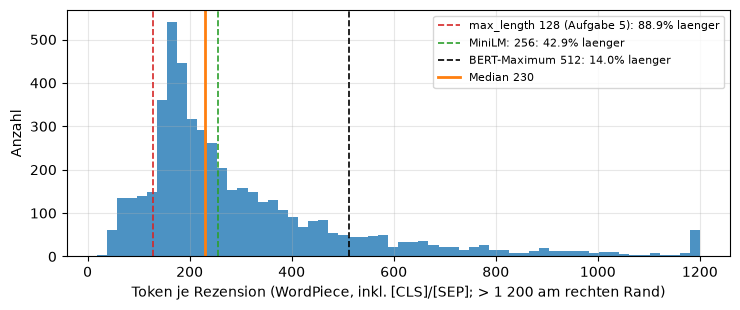

Median 230 | Mittel 308 | > 128: 88.9% | > 256: 42.9% | > 512: 14.0%


{'seed': 0,
 'torch': '2.8.0',
 'threads': 4,
 'config': {'korpus': {'low': 5,
   'lower': 2,
   'newest': 6,
   'widest': 3,
   'wet': 2},
  'woerter': ['unbelievably', 'Drehmomentschlüssel', '2026-10-22', '1e-3']},
 'bpe_regeln': [['t', '_'], ['w', 'e'], ['s', 't_']],
 'bpe_lowest': ['l', 'o', 'we', 'st_'],
 'zerlegung': {'unbelievably': {'WordPiece': ['un',
    '##bel',
    '##ie',
    '##va',
    '##bly'],
   'n WP': 5,
   'Byte-BPE': ['un', 'bel', 'iev', 'ably'],
   'n BPE': 4},
  'Drehmomentschlüssel': {'WordPiece': ['dr',
    '##eh',
    '##mo',
    '##ments',
    '##ch',
    '##lus',
    '##sel'],
   'n WP': 7,
   'Byte-BPE': ['D', 're', 'hm', 'om', 'ents', 'ch', 'l', 'Ã¼', 's', 'sel'],
   'n BPE': 10},
  '2026-10-22': {'WordPiece': ['202', '##6', '-', '10', '-', '22'],
   'n WP': 6,
   'Byte-BPE': ['20', '26', '-', '10', '-', '22'],
   'n BPE': 6},
  '1e-3': {'WordPiece': ['1', '##e', '-', '3'],
   'n WP': 4,
   'Byte-BPE': ['1', 'e', '-', '3'],
   'n BPE': 4}},
 'laengen_medi

In [11]:
# Vorgegeben: Histogramm mit den Schwellen 128 (Fine-Tuning), 256 (MiniLM) und 512 (BERT-Maximum)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(np.minimum(laengen, 1200), bins=60, color="C0", alpha=.8)
for x, lab, c in [(128, "max_length 128 (Aufgabe 5)", "C3"), (256, "MiniLM: 256", "C2"), (512, "BERT-Maximum 512", "k")]:
    ax.axvline(x, color=c, ls="--", lw=1.2, label=f"{lab}: {(laengen > x).mean():.1%} laenger")
ax.axvline(median_len, color="C1", lw=2, label=f"Median {median_len:.0f}")
ax.set_xlabel("Token je Rezension (WordPiece, inkl. [CLS]/[SEP]; > 1 200 am rechten Rand)"); ax.set_ylabel("Anzahl")
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print(f"Median {median_len:.0f} | Mittel {laengen.mean():.0f} | > 128: {anteil_128:.1%} | > 256: {(laengen > 256).mean():.1%} "
      f"| > 512: {anteil_512:.1%}")
save_log("a1_tokenisierung", config={"korpus": KORPUS, "woerter": WOERTER},
         bpe_regeln=[list(r) for r in regeln], bpe_lowest=bpe_tokenize("lowest", regeln),
         zerlegung={w: zerlege(w) for w in WOERTER}, laengen_median=median_len, laengen_mittel=laengen.mean(),
         anteil_gt128=anteil_128, anteil_gt256=(laengen > 256).mean(), anteil_gt512=anteil_512)

In [12]:
# Pruefzelle 1.3
check("1.3 Laengen fuer alle 5 000 Trainingstexte", lambda: len(laengen) == 5000)
check(f"1.3 Median ≈ 230 Token (gemessen {median_len:.0f})", lambda: 225 <= median_len <= 235,
      "ohne truncation zaehlen; [CLS]/[SEP] gehoeren dazu")
check(f"1.3 Anteil > 128 Token ≈ 89 % (gemessen {anteil_128:.1%})", lambda: 0.87 <= anteil_128 <= 0.91)
check(f"1.3 Anteil > 512 Token ≈ 14 % (gemessen {anteil_512:.1%})", lambda: 0.12 <= anteil_512 <= 0.16)

✅ 1.3 Laengen fuer alle 5 000 Trainingstexte
✅ 1.3 Median ≈ 230 Token (gemessen 230)
✅ 1.3 Anteil > 128 Token ≈ 89 % (gemessen 88.9%)
✅ 1.3 Anteil > 512 Token ≈ 14 % (gemessen 14.0%)


### Interpretation Aufgabe 1

- Warum gewinnt im ersten Schritt $(\texttt{t},\texttt{\_})$? Warum entsteht im Skript-Korpus ohne `wet` ein Gleichstand, und warum ist er dort unvermeidbar?
- `lowest` wird zu `l o we st_`. Sind BPE-Token Silben oder Morpheme? Was lernt BPE stattdessen?
- Warum zerlegt WordPiece `Drehmomentschlüssel` in sieben Stücke, und was passiert dabei mit dem `ü`? Warum kann Byte-Level-BPE jede Zeichenkette verlustfrei darstellen, und was kostet das?
- Median ≈ 230 Token, aber `max_length=128` in Aufgabe 5: Welcher Teil einer typischen Rezension geht verloren, und warum ist das eine Genauigkeits- und nicht nur eine Kostenfrage (Abschn. 8.4)?

**Antwort (Musterlösung):**


- **Warum $(\texttt{t},\texttt{\_})$:** Es kommt in `newest` (6), `widest` (3) und `wet` (2) vor, also $11\times$; $(\texttt{w},\texttt{e})$
  folgt mit 10 (`lower` 2, `newest` 6, `wet` 2), $(\texttt{e},\texttt{s})$ und $(\texttt{s},\texttt{t})$ mit je 9. Danach gewinnen
  $(\texttt{w},\texttt{e})$ (10) und $(\texttt{s},\texttt{t\_})$ (9 gegen 7). Im Skript-Korpus treten `e s`, `s t` und `t _` **nur** gemeinsam
  in `est_` auf; ihre Häufigkeiten sind daher bei jeder Wahl der Worthäufigkeiten gleich (je 9). Den Gleichstand bricht nur eine
  Konvention (z. B. das zuerst gefundene Paar) oder ein Wort, in dem eines der Paare allein vorkommt – hier `wet`.
- **Keine Morpheme:** `lowest` → `l o we st_`, `west` → `we st_`. BPE lernt Häufigkeit, nicht Bedeutung: `we` ist ein häufiges
  Zeichenpaar, kein Wortbaustein. Dass im Skript `est_` als Superlativsuffix entsteht, ist eine glückliche Folge der Statistik, kein
  Ziel des Algorithmus (Abschn. 2.3: „BPE stammt aus der Datenkompression“). Trotzdem ist jedes neue Wort darstellbar, notfalls zeichenweise.
- **WordPiece und `Drehmomentschlüssel`:** Das englische `uncased`-Vokabular (30 522 Einträge) enthält keine deutschen Komposita;
  greedy wird immer das längste bekannte Präfix gewählt: `dr ##eh ##mo ##ments ##ch ##lus ##sel` (7 Token). Die Normalisierung
  (Kleinschreibung, Akzente entfernen) macht aus `ü` ein `u`: Der Rückweg liefert `drehmomentschlussel`, Information ist verloren.
  Byte-Level-BPE (GPT-2) arbeitet auf den UTF-8-Bytes, das Grundvokabular hat 256 Einträge, also ist jede Zeichenkette verlustfrei
  darstellbar (alle vier Wörter kommen exakt zurück). Der Preis: `ü` sind zwei Byte-Token (`Ã¼`), das Wort braucht 10 Token,
  nicht-englische Texte werden lang (Abschn. 2.3, Byte-Level-BPE). Zahlen zerfallen bei beiden: `2026-10-22` in 6 Token.
- **Länge als Genauigkeitsfrage:** Median 230 Token, 88,9 % der Rezensionen sind länger als 128, 14,0 % länger als 512. Bei
  `max_length=128` sieht DistilBERT bei der Hälfte der Texte höchstens 56 % des Inhalts – und das Fazit steht bei Rezensionen oft
  am Ende (Abschn. 8.4). O2 bestätigt das: Für Texte > 256 Token fällt Stufe 2 auf 75,3 % (gegenüber 85,7 % bei 128–256 Token).

## Aufgabe 2 · Embeddings und Ähnlichkeit

`CODE` 2.1–2.4 · `DENKEN` Interpretation · Skript Abschn. 3.1, 3.3, 3.5 (Gl. 2, Gl. 4, Bsp. 3.2, Listing 2) · ≈ 7 Min. allein + 3 Min. Besprechung

**Lernziel** (Bloom: *Verstehen*, *Analysieren*): das Embedding als Zeilen-Lookup erklären, Kosinusähnlichkeit berechnen und an
Satz-Embeddings analysieren, *was* der Raum als ähnlich ansieht.

**Intuition.** Die Embedding-Matrix $\mathbf{E}$ ist ein Telefonbuch: Die Token-ID ist die Zeilennummer, die Zeile ist der Vektor.
Die Multiplikation mit einem One-Hot-Vektor (Gl. 2) schlägt genau eine Zeile nach. Ähnlichkeit misst man über den Winkel
zwischen zwei Vektoren, nicht über ihre Länge (Gl. 4):

$$\mathbf{x}_t=\mathbf{E}^\top\mathbf{e}_{w_t}=\mathbf{E}[w_t,:],\qquad
\cos(\mathbf{u},\mathbf{v})=\frac{\mathbf{u}^\top\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|}.$$

### 2.1 Embedding-Lookup = One-Hot × E

`CODE` · `nn.Embedding(10, 4)` hält $\mathbf{E}\in\mathbb{R}^{10\times4}$ in `emb.weight`. Bilden Sie die One-Hot-Matrix der IDs
($n\times|\mathcal{V}|$) und multiplizieren Sie mit $\mathbf{E}$. Das Ergebnis muss exakt `emb(ids)` sein – mit denselben Gewichten.

In [13]:
abschnitt("Aufgabe 2")
torch.manual_seed(0)
emb = nn.Embedding(10, 4)               # |V| = 10 Token, d = 4
ids = torch.tensor([3, 1, 4, 1, 5])     # eine Sequenz aus fuenf Token-IDs

def lookup_onehot(ids: torch.Tensor, E: torch.Tensor) -> torch.Tensor:
    """Gl. (2) fuer alle Positionen auf einmal: (n x |V|) One-Hot-Matrix mal E (|V| x d) -> (n x d)."""
    # TODO 2.1: F.one_hot(ids, num_classes=E.shape[0]) liefert 0/1-Eintraege als Ganzzahlen -> .float(), dann @ E
    # F.one_hot macht aus jeder ID eine Zeile mit genau einer 1: ID 3 -> [0, 0, 0, 1, 0, ...] (Laenge |V| = E.shape[0]).
    # Ergebnis: (n x |V|) als Ganzzahl-Tensor -> .float(), sonst scheitert das Matrixprodukt mit den float-Gewichten.
    # (n x |V|) @ (|V| x d) = (n x d): Die 1 in Zeile t "waehlt" genau die Zeile ids[t] aus E aus, alle anderen
    # Zeilen werden mit 0 multipliziert. nn.Embedding macht dasselbe als direkten Tabellenzugriff E[ids] -
    # gleiches Ergebnis, aber ohne die vielen Multiplikationen mit 0.
    return F.one_hot(ids, num_classes=E.shape[0]).float() @ E

In [14]:
# Pruefzelle 2.1
check("2.1 One-Hot x E hat die Form (5, 4)", lambda: lookup_onehot(ids, emb.weight).shape == (5, 4))
check("2.1 One-Hot x E == nn.Embedding (gleiche Gewichte, torch.allclose)",
      lambda: torch.allclose(lookup_onehot(ids, emb.weight), emb(ids)), "E = emb.weight verwenden, nicht neu initialisieren")
print(f"Zum Vergleich: BERT-base hat |V| x d = 30 522 x 768 = {30522 * 768:,} Embedding-Parameter".replace(",", " "))

✅ 2.1 One-Hot x E hat die Form (5, 4)
✅ 2.1 One-Hot x E == nn.Embedding (gleiche Gewichte, torch.allclose)
Zum Vergleich: BERT-base hat |V| x d = 30 522 x 768 = 23 440 896 Embedding-Parameter


### 2.2 Kosinusähnlichkeit (Gl. 4)

`CODE` · Prüffälle aus Bsp. 3.2: $\mathbf{u}=(1,2,2)^\top$, $\mathbf{v}=(2,1,2)^\top$ ergibt $8/9\approx0{,}89$; $\mathbf{w}=(-2,1,0)^\top$
steht senkrecht auf $\mathbf{u}$. Dazu zwei Grenzfälle: entgegengesetzt ($-1$) und gleiche Richtung bei anderer Länge ($+1$).

In [15]:
def cosine(a: np.ndarray, b: np.ndarray) -> float:
    """Kosinusaehnlichkeit nach Gl. (4)."""
    # TODO 2.2: Skalarprodukt a @ b geteilt durch das Produkt der Normen np.linalg.norm(a) * np.linalg.norm(b)
    # a @ b = Skalarprodukt (Summe der elementweisen Produkte): gross, wenn beide Vektoren in dieselbe Richtung zeigen.
    # Die Division durch beide Laengen (euklidische Normen) entfernt den Einfluss der Vektorlaenge - nur der Winkel zaehlt.
    # Wertebereich [-1, 1]: 1 = gleiche Richtung, 0 = orthogonal, -1 = entgegengesetzt.
    # float(...) macht aus dem NumPy-Skalar eine normale Python-Zahl.
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

In [16]:
# Pruefzelle 2.2
u, v, w = np.array([1., 2, 2]), np.array([2., 1, 2]), np.array([-2., 1, 0])
check("2.2 Bsp. 3.2: cos(u, v) = 8/9", lambda: np.isclose(cosine(u, v), 8 / 9))
check("2.2 Bsp. 3.2: cos(u, w) = 0 (senkrecht)", lambda: np.isclose(cosine(u, w), 0))
check("2.2 cos(u, -u) = -1 (entgegengesetzt)", lambda: np.isclose(cosine(u, -u), -1))
check("2.2 cos(u, 5u) = 1 (Laenge spielt keine Rolle)", lambda: np.isclose(cosine(u, 5 * u), 1))

✅ 2.2 Bsp. 3.2: cos(u, v) = 8/9
✅ 2.2 Bsp. 3.2: cos(u, w) = 0 (senkrecht)
✅ 2.2 cos(u, -u) = -1 (entgegengesetzt)
✅ 2.2 cos(u, 5u) = 1 (Laenge spielt keine Rolle)


### 2.3 Thema oder Stimmung? MiniLM auf sechs Sätzen

`CODE` · `all-MiniLM-L6-v2` bildet jeden Satz auf einen Vektor in $\mathbb{R}^{384}$ ab (Mean Pooling, normiert; Listing 2). Die sechs
Sätze kombinieren zwei Themen (Film, Essen) mit positiver und negativer Stimmung. Für normierte Vektoren ist die Kosinusmatrix einfach
$\mathbf{Z}\mathbf{Z}^\top$. **Leitfrage:** Liegen Sätze mit gleichem *Thema* oder mit gleicher *Stimmung* näher beieinander?
Heatmap und Mittelwerte je Paartyp sind vorgegeben; vergleichen Sie die drei Mittelwerte.

In [17]:
st_model = SentenceTransformer(str(MINILM), device="cpu")    # lokaler Ordner, kein Hub
print(f"MiniLM: max_seq_length {st_model.max_seq_length} | Dimension {st_model.encode(["Test"]).shape[1]}")
SAETZE = ["A wonderful film with brilliant acting.",        # Film  +
          "I loved every minute of this movie.",            # Film  +
          "A dull film with terrible acting.",              # Film  -
          "The food in this restaurant was delicious.",     # Essen +
          "The soup was cold and the waiter was rude.",     # Essen -
          "I hated every bite of this meal."]               # Essen -
THEMA, STIMMUNG = [0, 0, 0, 1, 1, 1], [1, 1, 0, 1, 0, 0]
KURZ = ["Film + (wonderful)", "Film + (loved)", "Film − (dull)", "Essen + (delicious)", "Essen − (soup)", "Essen − (hated)"]
# TODO 2.3: Z6 = st_model.encode(SAETZE, normalize_embeddings=True) (6 x 384), dann S6 = Z6 @ Z6.T (Kosinusmatrix)
# encode() tokenisiert die sechs Saetze, schickt sie durch MiniLM und mittelt die Token-Vektoren (Mean Pooling)
# zu einem Satzvektor je Satz -> Z6 hat die Form (6 x 384). normalize_embeddings=True bringt jede Zeile auf Laenge 1.
Z6 = st_model.encode(SAETZE, normalize_embeddings=True)
# Bei Laenge 1 ist der Nenner in Gl. (4) gleich 1, die Kosinusaehnlichkeit also einfach das Skalarprodukt.
# Z6 @ Z6.T berechnet alle 6 x 6 Paare auf einmal: S6[i, j] = cos(Satz i, Satz j).
# Die Diagonale ist 1 (jeder Satz mit sich selbst), die Matrix ist symmetrisch.
S6 = Z6 @ Z6.T

MiniLM: max_seq_length 256 | Dimension 384


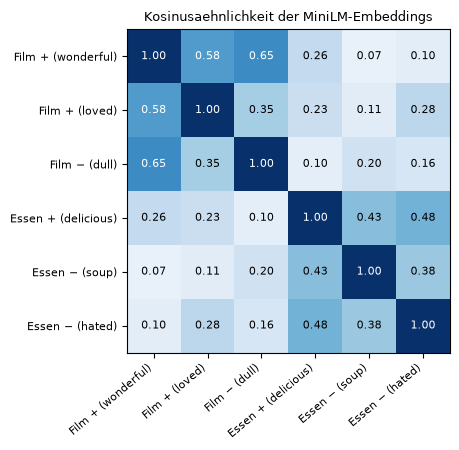

  gleiches Thema, andere Stimmung   : mittlerer Kosinus 0.48
  anderes Thema, gleiche Stimmung   : mittlerer Kosinus 0.21
  gleiches Thema, gleiche Stimmung  : mittlerer Kosinus 0.48


In [18]:
# Vorgegeben: Heatmap und Mittelwerte je Paartyp
heatmap(S6, KURZ, title="Kosinusaehnlichkeit der MiniLM-Embeddings", vmin=0, vmax=1); plt.tight_layout(); plt.show()
paare = [(i, j) for i in range(6) for j in range(i + 1, 6)]
mittel = lambda cond: np.mean([S6[i, j] for i, j in paare if cond(i, j)])
paartypen = {"gleiches Thema, andere Stimmung":   mittel(lambda i, j: THEMA[i] == THEMA[j] and STIMMUNG[i] != STIMMUNG[j]),
             "anderes Thema, gleiche Stimmung":   mittel(lambda i, j: THEMA[i] != THEMA[j] and STIMMUNG[i] == STIMMUNG[j]),
             "gleiches Thema, gleiche Stimmung":  mittel(lambda i, j: THEMA[i] == THEMA[j] and STIMMUNG[i] == STIMMUNG[j])}
for k, val in paartypen.items():
    print(f"  {k:34s}: mittlerer Kosinus {val:.2f}")

In [19]:
# Pruefzelle 2.3
check("2.3 Z6 hat die Form (6, 384) und Zeilen der Laenge 1", lambda: Z6.shape == (6, 384) and np.allclose(np.linalg.norm(Z6, axis=1), 1, atol=1e-5),
      "normalize_embeddings=True setzen")
check("2.3 S6 ist die Kosinusmatrix: S6[0, 2] == cosine(Z6[0], Z6[2]), Diagonale 1",
      lambda: np.isclose(S6[0, 2], cosine(Z6[0], Z6[2]), atol=1e-5) and np.allclose(np.diag(S6), 1, atol=1e-5))

✅ 2.3 Z6 hat die Form (6, 384) und Zeilen der Laenge 1
✅ 2.3 S6 ist die Kosinusmatrix: S6[0, 2] == cosine(Z6[0], Z6[2]), Diagonale 1


### 2.4 Rechenzeit und Referenz-Cache

`CODE` · Für die Aufgaben 4 und 6 brauchen wir die Embeddings **aller** 6 000 Texte. Sie liegen als **Referenz-Cache** in
`data/cache/emb_minilm.npy` bereit (einmal mit genau diesem Modell berechnet; Zeilen 0–4 999 = Train, 5 000–5 999 = Test).
Messen Sie, wie lange die ersten 200 Trainingstexte dauern, rechnen Sie auf 6 000 hoch und prüfen Sie, dass Ihre Vektoren mit dem Cache
übereinstimmen. Toleranz $10^{-4}$: Andere CPUs und Thread-Zahlen ändern die letzten Stellen der Gleitkommarechnung.

**Erwartung:** 200 Texte in ≈ 1,3 s im Lösungslauf (4 Threads), hochgerechnet 6 000 Texte ≈ 40 s; auf einem 4-Kern-Laptop ≈ 1,5–3 Min.
Abweichung zum Cache ≈ $10^{-7}$.

In [20]:
E_ref = np.load(EMB_CACHE)               # (6000, 384), float32, normiert
# TODO 2.4: t0 = time.perf_counter(); Z200 = st_model.encode(texts_tr[:200], batch_size=32, normalize_embeddings=True);
#           dt200 = Sekunden seit t0; Hochrechnung t_hoch = dt200 / 200 * 6000
# perf_counter() ist die genaueste Uhr fuer Laufzeitmessungen (monoton, hohe Aufloesung); sinnvoll sind nur Differenzen.
t0 = time.perf_counter()
# 200 Texte in Paketen zu 32 durch den Encoder: Batching nutzt die Matrixoperationen besser aus als 200 Einzelaufrufe.
# Texte, die laenger als max_seq_length sind, schneidet encode() dabei ab.
Z200 = st_model.encode(texts_tr[:200], batch_size=32, normalize_embeddings=True)
dt200 = time.perf_counter() - t0
# Lineare Hochrechnung: Zeit pro Text (dt200 / 200) mal 6 000 Texte. Das passt naeherungsweise, weil die 200 Texte
# dieselbe Laengenverteilung haben wie der Rest - und es zeigt, warum sich der Cache E_ref lohnt.
t_hoch = dt200 / 200 * 6000
print(f"200 Texte in {dt200:.1f} s ({dt200 / 200 * 1000:.1f} ms/Text) -> 6 000 Texte ≈ {t_hoch:.0f} s ≈ {t_hoch / 60:.1f} Min. "
      f"| max. Abweichung zum Cache {np.abs(Z200 - E_ref[:200]).max():.1e}")
save_log("a2_embeddings", config={"modell": "all-MiniLM-L6-v2", "batch_size": 32, "max_seq_length": st_model.max_seq_length},
         kosinus_6=S6, paartypen=paartypen, zeit_200_s=dt200, hochrechnung_6000_s=t_hoch,
         max_abweichung_cache=float(np.abs(Z200 - E_ref[:200]).max()))

200 Texte in 1.4 s (7.0 ms/Text) -> 6 000 Texte ≈ 42 s ≈ 0.7 Min. | max. Abweichung zum Cache 1.6e-07


{'seed': 0,
 'torch': '2.8.0',
 'threads': 4,
 'config': {'modell': 'all-MiniLM-L6-v2',
  'batch_size': 32,
  'max_seq_length': 256},
 'kosinus_6': array([[1.0000002 , 0.5800601 , 0.6479821 , 0.25577164, 0.07348072,
         0.10312228],
        [0.5800601 , 1.        , 0.35253146, 0.22552338, 0.10958549,
         0.27899134],
        [0.6479821 , 0.35253146, 1.        , 0.10031185, 0.19548337,
         0.1582122 ],
        [0.25577164, 0.22552338, 0.10031185, 1.0000001 , 0.42941853,
         0.47762465],
        [0.07348072, 0.10958549, 0.19548337, 0.42941853, 0.99999994,
         0.38122433],
        [0.10312228, 0.27899134, 0.1582122 , 0.47762465, 0.38122433,
         1.0000001 ]], dtype=float32),
 'paartypen': {'gleiches Thema, andere Stimmung': np.float32(0.4768892),
  'anderes Thema, gleiche Stimmung': np.float32(0.20874764),
  'gleiches Thema, gleiche Stimmung': np.float32(0.48064223)},
 'zeit_200_s': 1.3951872079633176,
 'hochrechnung_6000_s': 41.85561623889953,
 'max_abweichun

In [21]:
# Pruefzelle 2.4
check("2.4 Z200 hat die Form (200, 384)", lambda: Z200.shape == (200, 384))
check("2.4 eigene Embeddings == Referenz-Cache (np.allclose, atol=1e-4)", lambda: np.allclose(Z200, E_ref[:200], atol=1e-4),
      "texts_tr[:200] (nicht texts_te) und normalize_embeddings=True?")

✅ 2.4 Z200 hat die Form (200, 384)
✅ 2.4 eigene Embeddings == Referenz-Cache (np.allclose, atol=1e-4)


### Interpretation Aufgabe 2

- One-Hot × $\mathbf{E}$ ergibt exakt den Lookup. Warum rechnet `nn.Embedding` trotzdem keine Matrixmultiplikation, und was würde sie bei $|\mathcal{V}|=30\,522$ kosten?
- Ähnlichkeitsmatrix: Ordnet MiniLM die Sätze eher nach **Thema** oder nach **Stimmung**? Nennen Sie die drei Mittelwerte. Was bedeutet das für einen linearen Sentiment-Klassifikator auf diesen Embeddings (Aufgabe 4)?
- Wie lange würden alle 6 000 Texte auf Ihrem Rechner dauern? Warum lohnt es sich, Embeddings einmal zu berechnen und zu cachen (Merke-Box Abschn. 3.5)?

**Antwort (Musterlösung):**


- **Lookup statt Produkt:** One-Hot × $\mathbf{E}$ wählt genau eine Zeile aus (Gl. 2); gemessen identisch mit `nn.Embedding`.
  Als echtes Matrixprodukt kostete jede Position $|\mathcal{V}|\cdot d = 30\,522\cdot768\approx23{,}4$ Mio. Multiplikationen, fast alle mit
  0, und die One-Hot-Matrix belegte $n\times30\,522$ Werte. `nn.Embedding` liest die Zeile direkt (Speicherzugriff, $d$ Werte); der
  Gradient fließt ebenso nur in die benutzten Zeilen.
- **Thema vor Stimmung:** Mittlerer Kosinus 0,48 für gleiches Thema mit **anderer** Stimmung, 0,21 für gleiche Stimmung mit anderem
  Thema, 0,48 für beides gleich. „A wonderful film with brilliant acting“ liegt näher an „A dull film with terrible acting“ (0,65) als
  an „I loved every minute of this movie“ (0,58). MiniLM ist auf semantische Ähnlichkeit von Satzpaaren trainiert (Abschn. 3.5);
  Stimmung ist darin nur eine von vielen Richtungen. Ein linearer Kopf muss diese Richtung aus einem Raum herausschneiden, der vor
  allem nach Inhalt sortiert ist – eine Erklärung für die nur ≈ 79 % in Aufgabe 4 (O1 zeigt dasselbe: intra 0,30 gegen inter 0,29).
- **Cache:** 200 Texte in 1,3 s (6,5 ms/Text) → 6 000 Texte ≈ 39 s auf 4 Threads, auf einem 4-Kern-Laptop ≈ 1,5–3 Min. Die eigenen
  Vektoren stimmen mit dem Cache bis auf $1{,}6\cdot10^{-7}$ überein. Weil der Encoder eingefroren ist, ändern sich die Embeddings nie:
  einmal rechnen, dann kostet jedes Experiment mit dem Kopf Sekunden (Merke-Box Abschn. 3.5: Feature Store, Vektordatenbank).

## Aufgabe 3 · Self-Attention von Hand

`CODE` 3.1–3.5 · `PAPIER` 3.2 (Bsp. 5.3 nachvollziehen) · `DENKEN` Interpretation · Skript Abschn. 5.2–5.4, 6.2
(Def. 5.2, Gl. 9, 10, 14, Bsp. 5.3, Satz 5.4, Listing 3) · 3.1–3.4: ≈ 14 Min. allein + 6 Min. live (3.2) + 3 Min. Besprechung; 3.5 (nach der Positionskodierung): ≈ 4 Min. allein + 2 Min. Besprechung – **Kern der Woche**

**Lernziel** (Bloom: *Verstehen*): Self-Attention erklären – Scores, zeilenweise Softmax, gewichtete Summe, Maske – und begründen,
warum sie ohne Positionskodierung die Reihenfolge nicht sieht.

**Intuition.** Attention ist ein weiches Wörterbuch-Nachschlagen: Die **Query** fragt, die **Keys** antworten mit ihrer Passung
(Skalarprodukt), die **Values** liefern den Inhalt. Statt genau einen Eintrag zurückzugeben, mischt Attention alle Values,
gewichtet mit einer Softmax über die Passungen (Gl. 9):

$$\operatorname{Attn}(\mathbf{Q},\mathbf{K},\mathbf{V})=\underbrace{\operatorname{softmax}\Bigl(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d_k}}\Bigr)}_{\mathbf{A}}\mathbf{V},
\qquad \mathbf{Q}=\mathbf{X}\mathbf{W}^Q,\ \mathbf{K}=\mathbf{X}\mathbf{W}^K,\ \mathbf{V}=\mathbf{X}\mathbf{W}^V\ \text{(Gl. 10)}.$$

Alles in diesem Abschnitt ist NumPy auf Papiergröße; PyTorch dient nur zur Gegenprobe.

### 3.1 Numerisch stabile Softmax

`CODE` · $\operatorname{softmax}(\mathbf{x})_i=e^{x_i}/\sum_j e^{x_j}$. Direkt gerechnet läuft $e^{1000}$ über (`inf/inf = nan`). Weil
die Softmax sich nicht ändert, wenn man von allen Einträgen dieselbe Zahl abzieht, zieht man vorher das Maximum ab.

In [22]:
abschnitt("Aufgabe 3")
def softmax(x: np.ndarray, axis: int = -1) -> np.ndarray:
    """Numerisch stabile Softmax entlang `axis` (bei Matrizen: zeilenweise mit axis=-1)."""
    # TODO 3.1: z = np.exp(x - x.max(axis=axis, keepdims=True)); dann z / z.sum(axis=axis, keepdims=True)
    # Numerische Stabilitaet: vor dem exp den Maximalwert (je Zeile) abziehen. Das aendert das Ergebnis nicht, denn
    # e^(x-c) / Summe e^(x-c) = e^x / Summe e^x (der Faktor e^-c kuerzt sich), verhindert aber einen Ueberlauf:
    # np.exp(1000) waere inf, so ist der groesste vorkommende Wert np.exp(0) = 1.
    # keepdims=True laesst die reduzierte Achse mit Laenge 1 stehen (bei einer Matrix: n x 1), damit das
    # Broadcasting von jeder Zeile ihr eigenes Maximum abzieht.
    z = np.exp(x - x.max(axis=axis, keepdims=True))
    # Normieren: jede Zeile durch ihre Summe -> nichtnegative Werte mit Summe 1 (eine Wahrscheinlichkeitsverteilung).
    # Maskierte Eintraege (-inf) werden zu exp(-inf) = 0 und bekommen damit kein Gewicht.
    return z / z.sum(axis=axis, keepdims=True)

In [23]:
# Pruefzelle 3.1
with np.errstate(over="ignore", invalid="ignore"):
    print("naiv:", np.exp([1000., 1000.]) / np.exp([1000., 1000.]).sum(), "| stabil:", softmax(np.array([1000., 1000.])))
check("3.1 softmax([1000, 1000]) = [0.5, 0.5] (kein Ueberlauf)", lambda: np.allclose(softmax(np.array([1000., 1000.])), 0.5))
check("3.1 softmax(log [1, 2, 3]) = [1/6, 2/6, 3/6]", lambda: np.allclose(softmax(np.log([1., 2, 3])), np.array([1, 2, 3]) / 6))
check("3.1 softmax([0, -inf]) = [1, 0] (so wirkt spaeter die Maske)", lambda: np.allclose(softmax(np.array([0., -np.inf])), [1, 0]))
M_test = np.random.default_rng(0).standard_normal((3, 5))
check("3.1 zeilenweise wie torch.softmax(dim=-1)", lambda: np.allclose(softmax(M_test), torch.softmax(torch.tensor(M_test), -1).numpy()),
      "keepdims=True, sonst passen die Formen beim Abziehen nicht")

naiv: [nan nan] | stabil: [0.5 0.5]
✅ 3.1 softmax([1000, 1000]) = [0.5, 0.5] (kein Ueberlauf)
✅ 3.1 softmax(log [1, 2, 3]) = [1/6, 2/6, 3/6]
✅ 3.1 softmax([0, -inf]) = [1, 0] (so wirkt spaeter die Maske)
✅ 3.1 zeilenweise wie torch.softmax(dim=-1)


### 3.2 Skalierte Skalarprodukt-Attention (Gl. 9)

`PAPIER` + `CODE` · Rechnen Sie zuerst die erste Zeile von Bsp. 5.3 nach: Scores $(1,0,1)/\sqrt2$, Softmax $\approx(0{,}40;\,0{,}20;\,0{,}40)$,
Ausgabe $(0{,}60;\,0{,}40)$. Dann `sdpa(Q, K, V, mask=None)`: Die Maske ist eine Boolesche Matrix der Form $n\times m$; `True` heißt
„darf sehen“, verbotene Scores werden vor der Softmax auf $-\infty$ gesetzt (Abschn. 5.3, Listing 3).
Tragen Sie Ihre Papierrechnung in die nächste Zelle ein; die Prüfzelle vergleicht danach auch mit `F.scaled_dot_product_attention`.

**Ihre Papierrechnung 3.2 (Musterlösung)** – erste Query $\mathbf{q}_1=(1,0)$, $d_k=2$

| | Key 1 $(1,0)$ | Key 2 $(0,1)$ | Key 3 $(1,1)$ |
|---|---|---|---|
| Score $\mathbf{q}_1^\top\mathbf{k}_j/\sqrt2$ | 0,71 | 0 | 0,71 |
| $e^{\text{Score}}$ | 2,03 | 1 | 2,03 |
| Softmax (Summe 5,06) | 0,40 | 0,20 | 0,40 |

Ausgabe: $0{,}40\cdot(1,0)+0{,}20\cdot(0,1)+0{,}40\cdot(0{,}5;\,0{,}5)=(0{,}60;\,0{,}40)$.

In [24]:
# Bsp. 5.3: drei Positionen, d_k = d_v = 2 (Zeilen = Positionen)
Q_bsp = np.array([[1., 0], [0, 1], [1, 1]])
K_bsp = Q_bsp.copy()
V_bsp = np.array([[1., 0], [0, 1], [.5, .5]])

def sdpa(Q: np.ndarray, K: np.ndarray, V: np.ndarray, mask=None):
    """Gl. (9): A = softmax(Q K^T / sqrt(d_k)) zeilenweise, Ausgabe A V. mask: bool (n x m), True = erlaubt.
    Rueckgabe: (Ausgabe n x d_v, A n x m)."""
    # TODO 3.2: Scores S = Q @ K.T / np.sqrt(d_k) mit d_k = K.shape[-1]; falls mask nicht None:
    #           S = np.where(mask, S, -np.inf); dann A = softmax(S, axis=-1); zurueckgeben: A @ V, A
    # Scores: Q (n x d_k) @ K.T (d_k x m) = (n x m). S[i, j] misst per Skalarprodukt, wie gut Query i zu Key j passt.
    # Teilen durch sqrt(d_k): Ein Skalarprodukt aus d_k Summanden streut umso staerker, je groesser d_k ist
    # (Standardabweichung ~ sqrt(d_k)). Ohne Skalierung wird die Softmax bei grossem d_k fast zu einem harten
    # Maximum, und die Gradienten verschwinden (vgl. Optional O4).
    S = Q @ K.T / np.sqrt(K.shape[-1])
    if mask is not None:
        # Verbotene Positionen (mask == False) auf -inf setzen; nach der Softmax ist ihr Gewicht exakt 0.
        # np.where(Bedingung, wenn_wahr, wenn_falsch) arbeitet elementweise.
        S = np.where(mask, S, -np.inf)
    # Softmax zeilenweise (axis=-1): Jede Query verteilt eine Aufmerksamkeit von insgesamt 1 auf alle Keys.
    A = softmax(S, axis=-1)
    # A (n x m) @ V (m x d_v) = (n x d_v): Jede Ausgabezeile ist ein gewichteter Mittelwert der Value-Zeilen.
    # A wird mit zurueckgegeben, damit man die Aufmerksamkeitsgewichte ansehen und pruefen kann.
    return A @ V, A

In [25]:
# Pruefzelle 3.2
out_bsp, A_bsp = sdpa(Q_bsp, K_bsp, V_bsp)
print("A =\n", A_bsp.round(3), "\nAusgabe =\n", out_bsp.round(3))
print("ohne Skalierung waeren die Gewichte:\n", softmax(Q_bsp @ K_bsp.T).round(2))
check("3.2 Bsp. 5.3: Zeile 1 von A ≈ (0,40; 0,20; 0,40)", lambda: np.allclose(A_bsp[0], [.40, .20, .40], atol=.005),
      "durch np.sqrt(d_k) teilen, Softmax zeilenweise (axis=-1)")
check("3.2 Bsp. 5.3: Zeile 3 von A ≈ (0,25; 0,25; 0,50)", lambda: np.allclose(A_bsp[2], [.25, .25, .50], atol=.005))
check("3.2 Bsp. 5.3: Ausgabe Zeile 1 ≈ (0,60; 0,40), Zeile 3 = (0,50; 0,50)",
      lambda: np.allclose(out_bsp[0], [.60, .40], atol=.005) and np.allclose(out_bsp[2], [.5, .5], atol=.005))
check("3.2 jede Zeile von A summiert zu 1", lambda: np.allclose(A_bsp.sum(1), 1))
check("3.2 gleich F.scaled_dot_product_attention",
      lambda: np.allclose(out_bsp, F.scaled_dot_product_attention(*(torch.tensor(m) for m in (Q_bsp, K_bsp, V_bsp))).numpy()))

A =
 [[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]] 
Ausgabe =
 [[0.602 0.398]
 [0.398 0.602]
 [0.5   0.5  ]]
ohne Skalierung waeren die Gewichte:
 [[0.42 0.16 0.42]
 [0.16 0.42 0.42]
 [0.21 0.21 0.58]]
✅ 3.2 Bsp. 5.3: Zeile 1 von A ≈ (0,40; 0,20; 0,40)
✅ 3.2 Bsp. 5.3: Zeile 3 von A ≈ (0,25; 0,25; 0,50)
✅ 3.2 Bsp. 5.3: Ausgabe Zeile 1 ≈ (0,60; 0,40), Zeile 3 = (0,50; 0,50)
✅ 3.2 jede Zeile von A summiert zu 1
✅ 3.2 gleich F.scaled_dot_product_attention


### 3.3 Self-Attention auf „Hund beißt den Mann“ (Gl. 10)

`CODE` · Ein Spielzeug-Vokabular mit vier Wörtern, zufälliger Embedding-Matrix ($d=8$) und zufälligen Projektionen
$\mathbf{W}^Q,\mathbf{W}^K,\mathbf{W}^V\in\mathbb{R}^{8\times4}$. Bei *Self*-Attention entstehen Queries, Keys und Values aus **derselben**
Eingabe $\mathbf{X}$ (eine Zeile pro Token). Die Gewichte sind untrainiert, die Heatmap zeigt also kein Sprachwissen, sondern die Mechanik.
Die Heatmap von $\mathbf{A}$ ist vorgegeben. **Erwartung:** Ausgabe und $\mathbf{A}$ haben die Form $4\times4$, jede Zeile von $\mathbf{A}$ summiert zu 1.

In [26]:
rng = np.random.default_rng(0)
VOKAB = {"Hund": 0, "beißt": 1, "den": 2, "Mann": 3}
d, d_k = 8, 4
E_toy = rng.standard_normal((len(VOKAB), d))                         # Embedding-Matrix (4 x 8)
W_Q, W_K, W_V = (rng.standard_normal((d, d_k)) / np.sqrt(d) for _ in range(3))
satz = ["Hund", "beißt", "den", "Mann"]
X = E_toy[[VOKAB[t] for t in satz]]                                  # (4 x 8): Zeile t = Embedding von Token t

def self_attention(X: np.ndarray, W_Q, W_K, W_V, mask=None):
    """Gl. (10) + Gl. (9): Q, K, V aus derselben Sequenz X, dann sdpa. Rueckgabe: (Ausgabe n x d_k, A n x n)."""
    # TODO 3.3: Q = X @ W_Q, K = X @ W_K, V = X @ W_V; dann sdpa(Q, K, V, mask) zurueckgeben
    # "Self"-Attention: Queries, Keys und Values stammen alle aus DERSELBEN Sequenz X (n x d) - nur unterschiedlich
    # projiziert. Die drei gelernten Matrizen (d x d_k) geben jedem Token drei Rollen, jeweils (n x d_k):
    #   Q = "wonach suche ich?",  K = "wofuer stehe ich?",  V = "was gebe ich weiter?"
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V
    # Die eigentliche Gewichtung steckt in sdpa (Gl. 9); die Maske wird unveraendert durchgereicht.
    return sdpa(Q, K, V, mask)

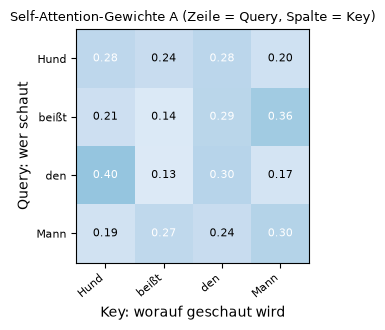

✅ 3.3 Ausgabe (4 x 4) und A (4 x 4)
✅ 3.3 Zeilensummen von A = 1
✅ 3.3 gleich F.scaled_dot_product_attention auf X W_Q, X W_K, X W_V


In [27]:
Y, A = self_attention(X, W_Q, W_K, W_V)
heatmap(A, satz, title="Self-Attention-Gewichte A (Zeile = Query, Spalte = Key)", vmin=0, vmax=1)
plt.xlabel("Key: worauf geschaut wird"); plt.ylabel("Query: wer schaut"); plt.tight_layout(); plt.show()
# Pruefzelle 3.3
check("3.3 Ausgabe (4 x 4) und A (4 x 4)", lambda: Y.shape == (4, 4) and A.shape == (4, 4))
check("3.3 Zeilensummen von A = 1", lambda: np.allclose(A.sum(1), 1))
check("3.3 gleich F.scaled_dot_product_attention auf X W_Q, X W_K, X W_V",
      lambda: np.allclose(Y, F.scaled_dot_product_attention(*(torch.tensor(X @ W) for W in (W_Q, W_K, W_V))).numpy()))

### 3.4 Kausale Maske

`CODE` · Ein Decoder darf beim Erzeugen von Token $t$ nur die Positionen $\le t$ sehen (Abschn. 5.3, 6.3). Die Maske ist eine **untere
Dreiecksmatrix**; oberhalb der Diagonale muss $\mathbf{A}$ danach exakt 0 sein, und jede Zeile summiert trotzdem zu 1.
**Erwartung:** erste Zeile $(1,0,0,0)$, zweite Zeile $\approx(0{,}61;\,0{,}39;\,0;\,0)$.

In [28]:
# TODO 3.4: kausale Maske (4 x 4, dtype=bool) mit np.tril(np.ones(...)) bauen und self_attention(..., mask=maske) aufrufen
# np.ones((4, 4), dtype=bool) ist eine 4 x 4-Matrix voller True; np.tril ("triangle lower") behaelt die untere
# Dreiecksmatrix inklusive Diagonale, alles darueber wird False. Zeile i = Query an Position i, Spalte j = Key an
# Position j: erlaubt ist nur j <= i. Jedes Token sieht also sich selbst und seine Vorgaenger, nie die Zukunft
# (so arbeiten Decoder wie GPT beim Erzeugen von Text).
maske = np.tril(np.ones((4, 4), dtype=bool))
# Gleiche Sequenz und gleiche Gewichte wie in 3.3, nur mit Maske. In A_k ist daher alles oberhalb der Diagonale 0,
# und die erste Zeile ist [1, 0, 0, 0]: "Hund" kann nur auf sich selbst achten.
Y_k, A_k = self_attention(X, W_Q, W_K, W_V, mask=maske)

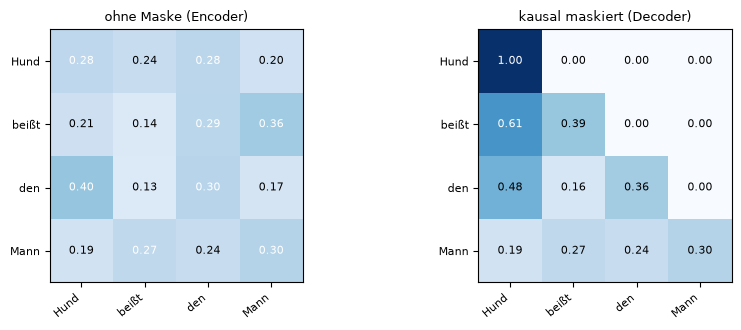

✅ 3.4 oberhalb der Diagonale ist A exakt 0
✅ 3.4 Zeilensummen weiterhin 1
✅ 3.4 das erste Token sieht nur sich selbst: A[0] = (1, 0, 0, 0)
✅ 3.4 gleich F.scaled_dot_product_attention(..., is_causal=True)


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
heatmap(A, satz, title="ohne Maske (Encoder)", ax=ax[0], vmin=0, vmax=1)
heatmap(A_k, satz, title="kausal maskiert (Decoder)", ax=ax[1], vmin=0, vmax=1)
plt.tight_layout(); plt.show()
# Pruefzelle 3.4
check("3.4 oberhalb der Diagonale ist A exakt 0", lambda: np.all(np.triu(A_k, 1) == 0), "np.tril (unten), nicht np.triu")
check("3.4 Zeilensummen weiterhin 1", lambda: np.allclose(A_k.sum(1), 1))
check("3.4 das erste Token sieht nur sich selbst: A[0] = (1, 0, 0, 0)", lambda: np.allclose(A_k[0], [1, 0, 0, 0]))
check("3.4 gleich F.scaled_dot_product_attention(..., is_causal=True)",
      lambda: np.allclose(Y_k, F.scaled_dot_product_attention(*(torch.tensor(X @ W) for W in (W_Q, W_K, W_V)), is_causal=True).numpy()))

### 3.5 Permutationstest (Satz 5.4) und Positionskodierung (Gl. 14)

`CODE` · „Mann beißt den Hund“ enthält dieselben Token in anderer Reihenfolge: $\mathbf{X}_\text{perm}=\mathbf{\Pi}\mathbf{X}$ mit
`perm = [3, 1, 2, 0]`. Nach Satz 5.4 werden die Ausgaben dann nur mitvertauscht. Mit der sinusförmigen Positionskodierung
$\mathbf{P}$ (Gl. 14, vorgegeben) addiert jede *Position* ihren eigenen Vektor – dann sollte die Gleichheit verschwinden.

**Erwartung:** ohne Positionskodierung $\max|f(\mathbf{\Pi}\mathbf{X})-\mathbf{\Pi}f(\mathbf{X})|\approx10^{-16}$, mit Positionskodierung ≈ 0,30.

In [30]:
def posenc(n: int, d: int) -> np.ndarray:
    """Sinusfoermige Positionskodierung nach Gl. (14): P[t, 2i] = sin(t / 10000^(2i/d)), P[t, 2i+1] = cos(...)."""
    t, i = np.arange(n)[:, None], np.arange(d // 2)[None, :]
    winkel = t / 10000 ** (2 * i / d)
    P = np.zeros((n, d)); P[:, 0::2], P[:, 1::2] = np.sin(winkel), np.cos(winkel)
    return P

satz_perm = ["Mann", "beißt", "den", "Hund"]
perm = [3, 1, 2, 0]                                    # neue Position i <- alte Position perm[i]
X_perm = E_toy[[VOKAB[t] for t in satz_perm]]
P = posenc(4, d)
print("X_perm == X[perm]:", np.allclose(X_perm, X[perm]), "| P[1, :2] =", P[1, :2].round(3), "(sin 1, cos 1)")
# TODO 3.5: vier Ausgaben von self_attention (nur Y behalten, A verwerfen: Y0, _ = ...):
#           Y0 fuer X, Y0p fuer X_perm (beide ohne Positionskodierung), Y1 fuer X + P, Y1p fuer X_perm + P
# Ohne Positionskodierung ist Self-Attention permutations-aequivariant: Vertauscht man die Eingabezeilen, vertauschen
# sich die Ausgabezeilen genauso (Y0p == Y0[perm]). Das Modell kann "Hund beißt den Mann" und "Mann beißt den Hund"
# nicht unterscheiden - es sieht nur eine Menge von Woertern, keine Reihenfolge.
Y0, _ = self_attention(X, W_Q, W_K, W_V)
Y0p, _ = self_attention(X_perm, W_Q, W_K, W_V)
# Mit Positionskodierung: P wird auf die Embeddings ADDIERT (gleiche Form n x d). Zeile t von P haengt nur von der
# Position t ab, nicht vom Wort. Nach dem Vertauschen steht "Mann" an Position 0 und bekommt P[0] statt P[3] ->
# andere Q, K, V -> die Ausgabe ist keine blosse Umordnung mehr (Y1p != Y1[perm]): Die Reihenfolge zaehlt jetzt.
Y1, _ = self_attention(X + P, W_Q, W_K, W_V)
Y1p, _ = self_attention(X_perm + P, W_Q, W_K, W_V)

X_perm == X[perm]: True | P[1, :2] = [0.841 0.54 ] (sin 1, cos 1)


In [31]:
abw_ohne, abw_mit = np.abs(Y0p - Y0[perm]).max(), np.abs(Y1p - Y1[perm]).max()
print(f"ohne Positionskodierung: max |f(ΠX) - Π f(X)| = {abw_ohne:.1e}  (aequivariant)")
print(f"mit  Positionskodierung: max |f(ΠX+P) - Π f(X+P)| = {abw_mit:.2f}  (Reihenfolge sichtbar)")
print("Ausgabe fuer 'Hund' in beiden Saetzen ohne PE:", Y0[0].round(3), "vs.", Y0p[3].round(3))
save_log("a3_attention", A_bsp=A_bsp, out_bsp=out_bsp, A_selbst=A, A_kausal=A_k,
         abweichung_ohne_pe=abw_ohne, abweichung_mit_pe=abw_mit)
# Pruefzelle 3.5
check("3.5 ohne PE: Ausgabe permutiert sich mit (Abweichung < 1e-10)", lambda: abw_ohne < 1e-10,
      "Y0p mit X_perm, verglichen wird mit Y0[perm]")
check("3.5 mit PE: Aequivarianz verloren (Abweichung > 0,01)", lambda: abw_mit > 0.01, "P zu X und zu X_perm addieren")

ohne Positionskodierung: max |f(ΠX) - Π f(X)| = 1.1e-16  (aequivariant)
mit  Positionskodierung: max |f(ΠX+P) - Π f(X+P)| = 0.30  (Reihenfolge sichtbar)
Ausgabe fuer 'Hund' in beiden Saetzen ohne PE: [-0.037 -0.173 -0.097  0.817] vs. [-0.037 -0.173 -0.097  0.817]
✅ 3.5 ohne PE: Ausgabe permutiert sich mit (Abweichung < 1e-10)
✅ 3.5 mit PE: Aequivarianz verloren (Abweichung > 0,01)


### Interpretation Aufgabe 3

- Warum teilt man durch $\sqrt{d_k}$? Was wäre bei $d_k=512$ ohne Skalierung mit der Softmax und ihrem Gradienten (Abschn. 5.2, Abb. 4)?
  Vergleichen Sie in Bsp. 5.3 die Gewichte mit und ohne Skalierung.
- Was bedeutet eine **Zeile** von $\mathbf{A}$, was eine **Spalte**? Warum summieren die Zeilen zu 1, die Spalten aber nicht?
- Wozu dient die kausale Maske, und warum setzt man die Scores auf $-\infty$, statt nachträglich Einträge von $\mathbf{A}$ auf 0 zu setzen?
- Warum ist Self-Attention ohne Positionskodierung blind für die Reihenfolge? Was bedeutet Ihr Ergebnis für „Hund beißt den Mann“ und „Mann beißt den Hund“, und wie ändert $\mathbf{P}$ das?

**Antwort (Musterlösung):**


- **$\sqrt{d_k}$:** Bei unabhängigen Komponenten mit Varianz 1 hat $\mathbf{q}^\top\mathbf{k}$ die Varianz $d_k$ (Abschn. 5.2). Bei
  $d_k=512$ liegen die Scores bei ±20, die Softmax wird praktisch One-Hot und ihr Gradient verschwindet. Schon bei $d_k=2$ ist der
  Effekt sichtbar: skaliert $(0{,}40;\,0{,}20;\,0{,}40)$, unskaliert $(0{,}42;\,0{,}16;\,0{,}42)$. O4 misst ihn: unskaliert fällt die
  Entropie von 3,7 Bit ($d_k=4$) auf 0,7 und 0,2 Bit ($d_k=64$, $512$), skaliert bleibt sie bei 4,4–4,6 Bit (Maximum 5).
- **Zeile und Spalte:** Zeile $i$ von $\mathbf{A}$ ist die Verteilung der Aufmerksamkeit von Query $i$ über alle Keys („wohin schaut
  Token $i$“); sie summiert durch die zeilenweise Softmax zu 1, die Ausgabe ist eine Konvexkombination der Values (Def. 5.1). Spalte $j$
  sagt, wie stark Token $j$ von allen anderen beachtet wird; dafür gibt es keine Normierung (gemessen z. B. Spaltensumme „den“ 1,10).
- **Kausale Maske:** Ein Decoder darf beim Training nicht das nächste Token ablesen (Abschn. 5.3). $-\infty$ vor der Softmax
  ergibt $e^{-\infty}=0$ und **renormiert** automatisch: Zeile 2 wird $(0{,}61;\,0{,}39;\,0;\,0)$ und summiert zu 1. Nullen nachträglich
  zu setzen hinterließe Zeilensummen < 1 und verzerrte die Mischung. Gemessen: oberhalb der Diagonale exakt 0, $\mathbf{A}_{1,:}=(1,0,0,0)$,
  identisch mit `is_causal=True`.
- **Blind für Reihenfolge:** Ohne Positionskodierung ist $f(\mathbf{\Pi}\mathbf{X})=\mathbf{\Pi}f(\mathbf{X})$ bis auf $1{,}1\cdot10^{-16}$
  (Satz 5.4): „Hund“ bekommt in „Hund beißt den Mann“ und „Mann beißt den Hund“ **denselben** Ausgabevektor, beide Sätze ergeben
  dieselbe Menge von Vektoren. Mit $\mathbf{P}$ (Gl. 14) addiert jede *Position* ihren eigenen Vektor; die Ausgaben weichen dann um 0,30
  ab – wer Subjekt ist, wird unterscheidbar (Abschn. 6.2).

## Aufgabe 4 · Stufe 1: eingefrorene Embeddings + logistische Regression

`CODE` 4.1, 4.2 · `DENKEN` Interpretation · Skript Abschn. 3.5, 7.4 (Zwei Regime, Tab. 5), 8.1 (lineare Sonde) · ≈ 6 Min. live (4.1) + 4 Min. allein (4.2) + 3 Min. Besprechung

**Lernziel** (Bloom: *Anwenden*, *Analysieren*): einen eingefrorenen Encoder als Feature-Extraktor nutzen, die Regularisierung per
Kreuzvalidierung wählen und an der Lernkurve analysieren, wie viel Sentiment-Information linear im Embedding-Raum steckt.

**Intuition.** Das ist das Trägermodell-Rezept aus der Vorwoche, nur für Text: Der vortrainierte Encoder bleibt eingefroren, seine
Ausgaben sind fertige Merkmale, und nur ein linearer Kopf wird trainiert – hier eine logistische Regression mit $384+1=385$ Parametern.
Weil die Embeddings im Cache liegen, kostet jedes Experiment Sekunden. Die Testmenge wird je Modell **genau einmal** ausgewertet;
$C$ wird nur per 5-facher Kreuzvalidierung auf dem Trainingsset gewählt ($C$ klein = starke Regularisierung).

### 4.1 Kreuzvalidierung und Test

`CODE` · Logistische Regression auf dem Referenz-Cache mit $C\in\{0{,}01;\,0{,}1;\,1;\,10\}$, 5-fache Kreuzvalidierung (Schleife mit
`cross_val_score`); das beste $C$ auf allen 5 000 Trainingstexten fitten und **einmal** auf dem Test auswerten.
**Erwartung:** CV 75,7 / 78,4 / 80,1 / 79,9 %, bestes $C=1$, Test 79,2 %, Fit in Sekundenbruchteilen.
Das Skript (Abschn. 9) nennt 82–86 %; warum es auf diesem Datensatz weniger ist, fragt die Interpretation.

In [32]:
abschnitt("Aufgabe 4")
E_tr, E_te = E_ref[:5000], E_ref[5000:]          # Referenz-Cache: dieselben Vektoren, die Sie in 2.4 selbst berechnet haben
CS = [0.01, 0.1, 1, 10]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_acc = {}
for C in CS:
    # TODO 4.1a: cross_val_score(LogisticRegression(C=C, max_iter=1000), E_tr, y_tr, cv=cv5) liefert 5 Fold-Genauigkeiten;
    #            deren Mittelwert in cv_acc[C] ablegen
    # C ist die INVERSE Regularisierungsstaerke: kleines C = starke L2-Strafe auf die Gewichte (einfacheres Modell),
    # grosses C = schwache Strafe. max_iter=1000, damit der Optimierer auf 384 Merkmalen sicher konvergiert.
    # cross_val_score trainiert 5-mal auf 4/5 der Trainingsdaten und misst jeweils auf dem fehlenden Fuenftel
    # (stratifiziert: gleiches pos/neg-Verhaeltnis in jedem Fold). Das Testset bleibt dabei unberuehrt.
    # .mean() ueber die 5 Fold-Genauigkeiten ist die Schaetzung fuer dieses C.
    cv_acc[C] = cross_val_score(LogisticRegression(C=C, max_iter=1000), E_tr, y_tr, cv=cv5).mean()
    print(f"  C = {C:<5}: CV-Genauigkeit {cv_acc[C]:.1%}")
C_best = max(cv_acc, key=cv_acc.get)
# TODO 4.1b: mit C_best auf ALLEN 5 000 Trainings-Embeddings fitten (Zeit t_lr messen) und EINMAL auf dem Test auswerten:
#            p1 = stufe1.predict_proba(E_te)[:, 1] (P(positiv)), acc1 = Anteil richtiger Vorhersagen (p1 > 0.5) == y_te
# Nach der Modellauswahl per CV: Endmodell mit dem besten C auf ALLEN 5 000 Trainingsvektoren neu fitten
# (mehr Daten als in jedem einzelnen Fold). Gemessen wird nur der Fit - die Embeddings sind schon berechnet.
t0 = time.perf_counter()
stufe1 = LogisticRegression(C=C_best, max_iter=1000).fit(E_tr, y_tr)
t_lr = time.perf_counter() - t0
# predict_proba liefert (n x 2): Spalte 0 = P(negativ), Spalte 1 = P(positiv). Wir behalten nur Spalte 1.
p1 = stufe1.predict_proba(E_te)[:, 1]
# Schwelle 0,5 -> harte Vorhersage (True/False); der Vergleich mit y_te (0/1) ergibt je Text richtig/falsch,
# .mean() = Genauigkeit. Das Testset wird hier genau EINMAL benutzt - jede Anpassung danach wuerde den Wert schoenen.
acc1 = ((p1 > 0.5) == y_te).mean()
print(f"bestes C = {C_best} | Fit {t_lr:.2f} s | Testgenauigkeit Stufe 1: {acc1:.1%}")

  C = 0.01 : CV-Genauigkeit 75.7%
  C = 0.1  : CV-Genauigkeit 78.4%
  C = 1    : CV-Genauigkeit 80.1%
  C = 10   : CV-Genauigkeit 79.9%
bestes C = 1 | Fit 0.00 s | Testgenauigkeit Stufe 1: 79.2%


In [33]:
# Pruefzelle 4.1
check("4.1 CV fuer alle vier C-Werte", lambda: sorted(cv_acc) == CS)
check(f"4.1 bestes C = 1 (CV {cv_acc.get(1, 0):.1%})", lambda: C_best == 1, "Mittelwert der Fold-Genauigkeiten je C, max waehlen")
check(f"4.1 Testgenauigkeit Stufe 1 ≈ 79 % (gemessen {acc1:.1%})", lambda: 0.78 <= acc1 <= 0.81,
      "auf E_tr/y_tr fitten, auf E_te/y_te bewerten (nicht vertauscht?)")
check("4.1 der Kopf hat 384 + 1 = 385 Parameter", lambda: stufe1.coef_.size + stufe1.intercept_.size == 385)

✅ 4.1 CV fuer alle vier C-Werte
✅ 4.1 bestes C = 1 (CV 80.1%)
✅ 4.1 Testgenauigkeit Stufe 1 ≈ 79 % (gemessen 79.2%)
✅ 4.1 der Kopf hat 384 + 1 = 385 Parameter


### 4.2 Lernkurve

`CODE` · Wie viel bringen mehr gelabelte Texte? Trainieren Sie den Kopf mit $C_\text{best}$ auf den ersten 100, 500, 1 000 und 2 000
Trainingstexten; der Punkt für 5 000 ist das Modell aus 4.1. Jedes $n$ ist ein eigenes Modell, das die Testmenge genau einmal sieht;
die Kurve ist eine **Diagnose**, keine Modellauswahl. Den Punkt $n=1\,000$ brauchen Sie in 5.3 für den fairen Vergleich.
Die Plotfunktion ist vorgegeben. **Erwartung:** 70,7 / 73,5 / 75,0 / 77,2 % für 100 / 500 / 1 000 / 2 000 Texte (5 000: 79,2 %).

In [34]:
GROESSEN = [100, 500, 1000, 2000]
lernkurve, pred_lk = {}, {}
for n in GROESSEN:
    # TODO 4.2: LogisticRegression(C=C_best, max_iter=1000) auf E_tr[:n], y_tr[:n] fitten; Testvorhersage (predict)
    #           in pred_lk[n], Testgenauigkeit in lernkurve[n]
    # Gleiche Konfiguration wie in 4.1 (C_best), aber nur die ersten n Trainingsbeispiele: So sieht man, wie die
    # Testgenauigkeit mit der Datenmenge waechst. Die Embeddings bleiben fest - nur der lineare Kopf lernt.
    clf = LogisticRegression(C=C_best, max_iter=1000).fit(E_tr[:n], y_tr[:n])
    # predict() liefert harte Klassen 0/1 (intern: P(positiv) > 0,5). Gespeichert fuer den paarweisen Vergleich danach.
    pred_lk[n] = clf.predict(E_te)
    # Anteil richtiger Vorhersagen auf demselben festen Testset -> die Punkte der Lernkurve sind direkt vergleichbar.
    lernkurve[n] = (pred_lk[n] == y_te).mean()
lernkurve[5000], pred_lk[5000] = acc1, (p1 > 0.5).astype(int)       # Modell aus 4.1, nicht neu bewerten

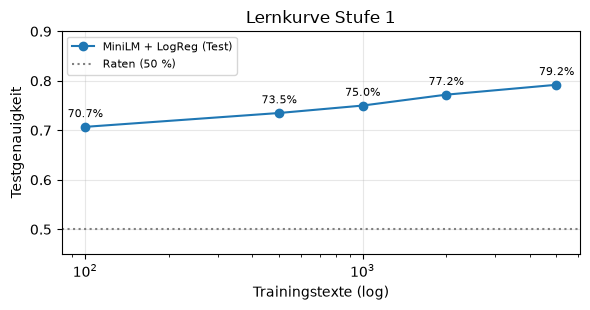

✅ 4.2 Lernkurve fuer 100, 500, 1 000, 2 000, 5 000
✅ 4.2 mehr Daten helfen: 100 < 1 000 < 5 000 Texte


In [35]:
# Vorgegeben: Plot und Log
fig, ax = plt.subplots(figsize=(6, 3.2))
ns = sorted(lernkurve)
ax.semilogx(ns, [lernkurve[n] for n in ns], "o-", label="MiniLM + LogReg (Test)")
for n in ns:
    ax.annotate(f"{lernkurve[n]:.1%}", (n, lernkurve[n]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.axhline(0.5, color="gray", ls=":", label="Raten (50 %)")
ax.set_xlabel("Trainingstexte (log)"); ax.set_ylabel("Testgenauigkeit"); ax.set_ylim(0.45, 0.9); ax.grid(alpha=.3)
ax.legend(fontsize=8); ax.set_title("Lernkurve Stufe 1"); plt.tight_layout(); plt.show()
save_log("a4_stufe1", config={"C_grid": CS, "cv": "StratifiedKFold(5, shuffle, Seed 0)", "max_iter": 1000},
         cv=cv_acc, C_best=C_best, test_acc=acc1, fit_zeit_s=t_lr, lernkurve=lernkurve, test_proba=p1)
# Pruefzelle 4.2
check("4.2 Lernkurve fuer 100, 500, 1 000, 2 000, 5 000", lambda: sorted(lernkurve) == [100, 500, 1000, 2000, 5000])
check("4.2 mehr Daten helfen: 100 < 1 000 < 5 000 Texte", lambda: lernkurve[100] < lernkurve[1000] < lernkurve[5000])

### Interpretation Aufgabe 4

- Welches $C$ gewinnt, und wie groß sind die Unterschiede in der Kreuzvalidierung? Was hieße es, wenn $C=0{,}01$ gewonnen hätte?
- Lernkurve: Wie viel bringt jede Verzehnfachung der Trainingsdaten? Ab wann lohnt es sich nicht mehr, Labels zu sammeln?
- Sie messen ≈ 79 %. Das Skript (Abschn. 9, Aufgabe 2) erwartet 82–86 %. Nennen Sie zwei Gründe, die Sie in diesem Lab selbst gesehen haben (Aufgabe 1.3: `max_seq_length` 256; Aufgabe 2.3: Thema oder Stimmung?). Was sagt die lineare Sonde (Abschn. 8.1) über den Embedding-Raum?

**Antwort (Musterlösung):**


- **Bestes $C$:** CV 75,7 / 78,4 / **80,1** / 79,9 % für $C=0{,}01$ / 0,1 / **1** / 10. Starke Regularisierung schadet deutlich, ab $C=1$
  ist die Kurve flach: 385 Parameter auf 5 000 Beispielen überanpassen kaum. Hätte $C=0{,}01$ gewonnen, wäre das ein Zeichen für
  sehr wenig oder sehr verrauschte Information im Raum. Test einmal: **79,2 %** (Fit in 3 ms, Tab. 5: „Kopf: Sekunden“).
- **Lernkurve:** 70,7 % (100) → 73,5 % (500) → 75,0 % (1 000) → 77,2 % (2 000) → 79,2 % (5 000), also ≈ +4–5 Punkte je Verzehnfachung.
  Schon 100 Labels liegen 20 Punkte über Raten (Tab. 5: „ab ∼ 100 Beispielen“); weitere Labels bringen wenig, der Raum selbst begrenzt.
- **79 % statt 82–86 %:** (1) MiniLM schneidet nach `max_seq_length` 256 Token ab, 42,9 % der Rezensionen sind länger (1.3); Mean Pooling
  über 256 Token verdünnt zudem einzelne wertende Sätze. (2) Der Raum ordnet nach Thema, nicht nach Stimmung (2.3; O1: Kosinus innerhalb
  der Klassen 0,30 gegen 0,29 zwischen den Klassen). Die lineare Sonde (Abschn. 8.1) zeigt also: Sentiment ist nur teilweise *linear*
  im Embedding enthalten – genau der Fall, in dem Fine-Tuning Potenzial hat. Die Skript-Erwartung ist auf diesem Datensatz zu optimistisch.

## Aufgabe 5 · Stufe 2: DistilBERT feinjustieren

`CODE` 5.1–5.3 · `AUSFÜHREN` Training · `DENKEN` Interpretation · Skript Abschn. 7.2, 7.4, 7.5 (Listing 5, Tab. 5) · ≈ 6 Min. live (5.1, 5.2) + 4 Min. allein (5.3) + 5 Min. Besprechung,
Rechenzeit ≈ 1,5–3 Min.

**Lernziel** (Bloom: *Anwenden*): einen vortrainierten Text-Classifier feinjustieren – Kopf anlegen, Optimierer und Lernratenplan
wählen, fair gegen die Baseline auswerten.

**Intuition.** Jetzt wird nicht nur der Kopf trainiert, sondern der ganze Encoder: alle 66 Mio. Parameter bewegen sich ein wenig in
Richtung „Sentiment“. Weil das vortrainierte Modell schon in einem guten Minimum steht, sind die Schritte klein (Lernrate $5\cdot10^{-5}$,
Abschn. 7.4); ein kurzer Warmup verhindert, dass der zufällige Kopf in den ersten Schritten den Encoder „verbiegt“.

**Lab-Konfiguration (Budget ≤ 5 Min. auf 4 Kernen):** die ersten **1.000** Trainingstexte, `max_length=128`, **Batch 8**, **1 Epoche**
= 125 Schritte; Validierung auf den Trainingstexten 1.000–1.249 (nicht im Training). Das Skript nennt 2.000 Texte mit Batch 16; das
hätte die doppelte Rechenzeit. Batch 8 kostet bei gleicher Textzahl kaum mehr Zeit als Batch 16, macht aber doppelt so viele
Optimiererschritte – bei nur einer Epoche auf 1.000 Texten bringt das im Mittel über drei Seeds ≈ 2 Prozentpunkte.

### 5.1 Modell laden

`CODE` · `AutoModelForSequenceClassification` setzt auf den Encoder einen zufällig initialisierten Klassifikationskopf. Die Warnung
**„Some weights … are newly initialized: classifier…, pre_classifier…“ ist erwartet** (Skript Tab. 7): Genau diese Schichten lernt das
Fine-Tuning neu. Vor dem Training rät das Modell, der Verlust muss also bei $\ln 2\approx0{,}693$ liegen.
**Erwartung:** 66.955.010 trainierbare Parameter, davon 592.130 im neuen Kopf; Verlust vor dem Training 0,691.

In [36]:
abschnitt("Aufgabe 5")
assert DBERT_OK, "DistilBERT-Gewichte fehlen: zuerst setup_check.ipynb ausfuehren (siehe Aufgabe 0)."
N_FT, N_VAL, MAXLEN, BS, EPOCHEN = 1000, 250, 128, 8, 1
torch.manual_seed(0)                       # Kopf-Initialisierung und Reihenfolge der Batches reproduzierbar
loaders = {"train": text_loader(tok_wp, texts_tr[:N_FT], y_tr[:N_FT], MAXLEN, BS, shuffle=True),
           "val":   text_loader(tok_wp, texts_tr[N_FT:N_FT + N_VAL], y_tr[N_FT:N_FT + N_VAL], MAXLEN, 64),
           "test":  text_loader(tok_wp, texts_te, y_te, MAXLEN, 64)}
# TODO 5.1: hf = AutoModelForSequenceClassification.from_pretrained(DBERT, num_labels=2), in HFClassifier(hf) einpacken
#           -> model_ft; trainierbare Parameter zaehlen: n_train_ft = sum(p.numel() for p in ... if p.requires_grad)
# from_pretrained laedt den vortrainierten DistilBERT-Encoder aus dem lokalen Ordner und setzt einen NEUEN, zufaellig
# initialisierten Klassifikationskopf mit num_labels=2 Ausgaben (Logits fuer neg/pos) darauf.
# HFClassifier (Setup-Zelle) ist eine duenne Huelle: model_ft(x) gibt direkt die Logits zurueck, damit fit() und
# predict() aus Lab 1 unveraendert funktionieren. Das Hugging-Face-Modell selbst liegt in model_ft.hf.
model_ft = HFClassifier(AutoModelForSequenceClassification.from_pretrained(DBERT, num_labels=2))
# Beim Fine-Tuning sind standardmaessig ALLE Gewichte trainierbar (requires_grad=True) - Encoder und Kopf.
# numel() = Anzahl Zahlen eines Tensors; die Summe ist die Zahl der Parameter, die der Optimierer anpasst
# (zum Vergleich Stufe 1: dort lernten nur 385 Zahlen = 384 Gewichte + 1 Bias).
n_train_ft = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at /Users/stefan/Documents/02_PHWT/DS-Vorlesung/03_Git_Studierende/data/models/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [37]:
# Vorgegeben: neue Kopf-Parameter und Verlust vor dem Training (erster Validierungs-Batch, ohne Gradient)
kopf = {n: p.numel() for n, p in model_ft.hf.named_parameters() if "classifier" in n}
print(f"trainierbar: {n_train_ft:,} | davon neu im Kopf: {sum(kopf.values()):,} {kopf}".replace(",", " "))
x0, yb0 = next(iter(loaders["val"]))
model_ft.eval()
with torch.inference_mode():
    loss0 = lossf(model_ft(x0), yb0).item()
print(f"Verlust vor dem Training: {loss0:.3f} (ln 2 = {math.log(2):.3f})")
# Pruefzelle 5.1
check("5.1 DistilBERT + Kopf: 66.955.010 trainierbare Parameter", lambda: n_train_ft == 66_955_010,
      "num_labels=2; alle Parameter zaehlen, deren requires_grad True ist")
check(f"5.1 Verlust vor dem Training ≈ ln 2 (gemessen {loss0:.3f})", lambda: abs(loss0 - math.log(2)) < 0.05)

trainierbar: 66 955 010 | davon neu im Kopf: 592 130 {'pre_classifier.weight': 589824  'pre_classifier.bias': 768  'classifier.weight': 1536  'classifier.bias': 2}
Verlust vor dem Training: 0.691 (ln 2 = 0.693)
✅ 5.1 DistilBERT + Kopf: 66 955 010 trainierbare Parameter
✅ 5.1 Verlust vor dem Training ≈ ln 2 (gemessen 0.691)


### 5.2 Training

`CODE` · Sie setzen nur Optimierer, Lernrate und Lernratenplan nach Skript Abschn. 7.4: **AdamW**, $\epsilon=5\cdot10^{-5}$, linearer
Warmup über die ersten 10 % der Schritte, danach linearer Abfall auf 0 (`get_linear_schedule_with_warmup`). Die Trainingsschleife ist
`fit` aus Lab 1, unverändert. Damit der Lernratenplan nach **jedem** Optimiererschritt weiterzählt, hängt die vorgegebene Zelle
`sched.step()` als *post hook* an den Optimierer. **Erwartung:** 125 Schritte, im Lösungslauf 43 s (4 Threads), auf einem
4-Kern-Laptop ≈ 1,5–3 Min.; Validierungsgenauigkeit ≈ 82 %.

**Während das Training läuft (≈ 1,5–3 Min.):** Lesen Sie schon die Leitfragen zu Aufgabe 5 und notieren Sie Ihre Vermutung.
**Notbremse:** Dauert ein Schritt bei Ihnen deutlich über 3 s, vor dem Ausführen `FREEZE = 3` setzen (friert Embeddings und die
Schichten 0–2 ein, ≈ 25 % schneller, ≈ 1 Prozentpunkt weniger) oder mit `lade_referenz("a5_finetune")` weiterarbeiten.

In [38]:
FREEZE = 0      # Notbremse fuer langsame Rechner: 3 = Embeddings + Encoder-Schichten 0-2 einfrieren
if FREEZE:
    for p in model_ft.hf.distilbert.embeddings.parameters():
        p.requires_grad = False
    for layer in model_ft.hf.distilbert.transformer.layer[:FREEZE]:
        for p in layer.parameters():
            p.requires_grad = False
n_steps = len(loaders["train"]) * EPOCHEN
# TODO 5.2: opt = torch.optim.AdamW(<nur trainierbare Parameter>, lr=5e-5);
#           sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=int(0.1 * n_steps), num_training_steps=n_steps)
# AdamW = Adam mit entkoppeltem Weight Decay, der Standard fuer das Fine-Tuning von Transformern.
# Nur Parameter mit requires_grad uebergeben: Bei FREEZE > 0 sind Teile eingefroren und brauchen keinen Optimiererzustand.
# lr = 5e-5 ist bewusst klein: Die vortrainierten Gewichte sind schon gut und sollen nur leicht verschoben werden;
# eine zu grosse Lernrate (z. B. 5e-3) zerstoert das Vortraining, der Verlust bleibt dann bei ≈ 0,69 (= Raten).
opt = torch.optim.AdamW([p for p in model_ft.parameters() if p.requires_grad], lr=5e-5)
# Lernraten-Plan: in den ersten 10 % der Schritte linear von 0 auf 5e-5 hochfahren (Warmup - der zufaellige Kopf
# erzeugt anfangs grosse, unruhige Gradienten), danach linear bis 0 am letzten Schritt absenken.
# sched.step() ruft der Hook in der naechsten Zelle nach jedem opt.step() auf.
sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=int(0.1 * n_steps), num_training_steps=n_steps)

In [39]:
# Vorgegeben: Training mit fit() aus Lab 1. Der Hook ruft nach jedem opt.step() sched.step() auf und meldet den Fortschritt.
fortschritt = {"n": 0, "t0": time.perf_counter()}
def _nach_schritt(optimizer, args, kwargs):
    sched.step(); fortschritt["n"] += 1
    if fortschritt["n"] % 10 == 0 or fortschritt["n"] == n_steps:
        print(f"    Schritt {fortschritt['n']:3d}/{n_steps} | Lernrate {sched.get_last_lr()[0]:.1e} | "
              f"{time.perf_counter() - fortschritt['t0']:.0f} s")
hook = opt.register_step_post_hook(_nach_schritt)
t0 = time.perf_counter()
hist_ft = fit(model_ft, opt, loaders, epochs=EPOCHEN)
t_ft = time.perf_counter() - t0
hook.remove()
print(f"Training: {n_steps} Schritte in {t_ft:.0f} s ({t_ft / n_steps:.2f} s/Schritt, inkl. Validierung)")
# Pruefzelle 5.2
check("5.2 1 000 Texte, Batch 8, 1 Epoche = 125 Schritte", lambda: n_steps == 125 and fortschritt["n"] == 125)
check("5.2 Lernrate am Ende auf 0 abgefallen (linearer Plan)", lambda: sched.get_last_lr()[0] == 0,
      "num_training_steps=n_steps; der Hook muss registriert sein")
check(f"5.2 Validierungsgenauigkeit > 75 % (gemessen {hist_ft['val_acc'][-1]:.1%})", lambda: hist_ft["val_acc"][-1] > 0.75,
      "Lernrate 5e-5 (nicht 5e-3)? Verlust bei 0,69 = nichts gelernt (Skript Tab. 7)")

    Schritt  10/125 | Lernrate 4.2e-05 | 3 s
    Schritt  20/125 | Lernrate 4.6e-05 | 7 s
    Schritt  30/125 | Lernrate 4.2e-05 | 10 s
    Schritt  40/125 | Lernrate 3.8e-05 | 13 s
    Schritt  50/125 | Lernrate 3.3e-05 | 17 s
    Schritt  60/125 | Lernrate 2.9e-05 | 20 s
    Schritt  70/125 | Lernrate 2.4e-05 | 24 s
    Schritt  80/125 | Lernrate 2.0e-05 | 27 s
    Schritt  90/125 | Lernrate 1.5e-05 | 30 s
    Schritt 100/125 | Lernrate 1.1e-05 | 34 s
    Schritt 110/125 | Lernrate 6.6e-06 | 37 s
    Schritt 120/125 | Lernrate 2.2e-06 | 41 s
    Schritt 125/125 | Lernrate 0.0e+00 | 42 s
  Epoche   1: train loss 0.5172 acc 72.70% | val loss 0.3778 acc 82.40% | 44.2s
Training: 125 Schritte in 44 s (0.35 s/Schritt, inkl. Validierung)
✅ 5.2 1 000 Texte, Batch 8, 1 Epoche = 125 Schritte
✅ 5.2 Lernrate am Ende auf 0 abgefallen (linearer Plan)
✅ 5.2 Validierungsgenauigkeit > 75 % (gemessen 82.4%)


### 5.3 Testgenauigkeit und fairer Vergleich

`CODE` · Die Testmenge wird für DistilBERT **genau einmal** ausgewertet. Fair ist der Vergleich nur mit dem Stufe-1-Modell auf
**denselben 1 000** Trainingstexten (Lernkurvenpunkt aus 4.2); die Stufe 1 mit 5 000 Texten steht als dritte Zeile daneben.
Tabelle und Konfusionsmatrizen sind vorgegeben.
**Erwartung:** Test 81,8 % (über drei Seeds 79,7–81,8 %); Stufe 1 auf denselben 1 000 Texten 75,0 %, mit 5 000 Texten 79,2 %;
Konfusionsmatrix 428 / 72 (wahr negativ) und 110 / 390 (wahr positiv). Das Skript erwartet ≥ 86 % für 2 000 Texte; die ausführliche
Fassung dieses Labs maß dort 82,8 %.

In [40]:
# TODO 5.3: p2 = predict(model_ft, loaders["test"]) (P(positiv), genau EINMAL), pred2 = (p2 > 0.5).astype(int),
#           acc2 = Anteil pred2 == y_te, cm2 = confusion_matrix(y_te, pred2)
# predict (Setup-Zelle) schaltet in den Eval-Modus (kein Dropout), rechnet ohne Gradienten ueber alle Test-Batches
# und liefert P(positiv) je Text. Genau EINMAL auf dem Testset - Entscheidungen fielen vorher auf dem Validierungsset.
p2 = predict(model_ft, loaders["test"])
# Gleiche Entscheidungsregel wie bei Stufe 1 (Schwelle 0,5); astype(int) macht aus True/False die Labels 1/0.
pred2 = (p2 > 0.5).astype(int)
acc2 = (pred2 == y_te).mean()
# Konfusionsmatrix: Zeilen = wahre Klasse, Spalten = vorhergesagte Klasse (0 = neg, 1 = pos).
# cm2[0, 1] = falsch positiv, cm2[1, 0] = falsch negativ - zeigt, ob das Modell eine Klasse bevorzugt.
cm2 = confusion_matrix(y_te, pred2)

,Testgenauigkeit,trainierbare Param.
"Stufe 1: MiniLM + LogReg, 1 000 Texte (fair)",75.0%,385
"Stufe 2: DistilBERT-FT, 1 000 Texte",81.8%,"66,955,010"
"Stufe 1: MiniLM + LogReg, 5 000 Texte",79.2%,385


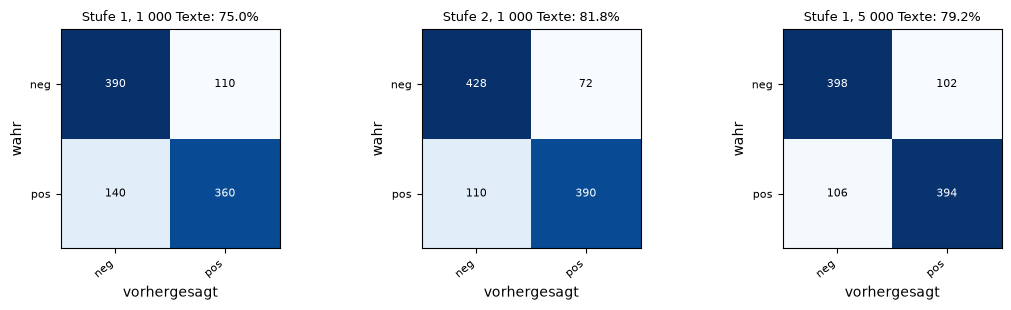

✅ 5.3 1 000 Testvorhersagen, Konfusionsmatrix summiert zu 1 000
✅ 5.3 Testgenauigkeit Stufe 2 ≥ 79 % (gemessen 81.8%; ueber Seeds 80-82 %)
✅ 5.3 fair verglichen: Fine-Tuning schlaegt Stufe 1 auf denselben 1 000 Texten


In [41]:
# Vorgegeben: Vergleichstabelle, Konfusionsmatrizen, Log
vergleich = pd.DataFrame({
    "Stufe 1: MiniLM + LogReg, 1 000 Texte (fair)": {"Testgenauigkeit": lernkurve[1000], "trainierbare Param.": 385},
    "Stufe 2: DistilBERT-FT, 1 000 Texte":          {"Testgenauigkeit": acc2, "trainierbare Param.": n_train_ft},
    "Stufe 1: MiniLM + LogReg, 5 000 Texte":        {"Testgenauigkeit": acc1, "trainierbare Param.": 385}}).T
display(vergleich.style.format({"Testgenauigkeit": "{:.1%}", "trainierbare Param.": "{:,.0f}"}))
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, (name, pr) in zip(ax, [("Stufe 1, 1 000 Texte", pred_lk[1000]), ("Stufe 2, 1 000 Texte", pred2),
                              ("Stufe 1, 5 000 Texte", pred_lk[5000])]):
    heatmap(confusion_matrix(y_te, pr), ["neg", "pos"], title=f"{name}: {(pr == y_te).mean():.1%}", ax=a, fmt="{:d}")
    a.set_xlabel("vorhergesagt"); a.set_ylabel("wahr")
plt.tight_layout(); plt.show()
save_log("a5_finetune", hist_ft, config={"modell": "distilbert-base-uncased", "n_train": N_FT, "val": "Train 1000-1249",
         "max_length": MAXLEN, "batch": BS, "epochen": EPOCHEN, "optimierer": "AdamW", "lr": 5e-5,
         "scheduler": "linear, 10 % Warmup", "schritte": n_steps, "freeze": FREEZE},
         loss0=loss0, runtime_s=t_ft, s_pro_schritt=t_ft / n_steps, trainierbare_parameter=n_train_ft,
         test_acc=acc2, konfusion=cm2, test_acc_stufe1_fair=lernkurve[1000], test_proba=p2)
# Pruefzelle 5.3
check("5.3 1 000 Testvorhersagen, Konfusionsmatrix summiert zu 1 000", lambda: len(p2) == 1000 and cm2.sum() == 1000)
check(f"5.3 Testgenauigkeit Stufe 2 ≥ 79 % (gemessen {acc2:.1%}; ueber Seeds 80-82 %)", lambda: acc2 >= 0.79,
      "Lernrate 5e-5, Warmup 10 %, Batch 8? Test nur einmal auswerten")
check("5.3 fair verglichen: Fine-Tuning schlaegt Stufe 1 auf denselben 1 000 Texten", lambda: acc2 > lernkurve[1000])

### Interpretation Aufgabe 5

- Warum liegt der Verlust vor dem Training bei $\ln 2$? Wie viele Parameter sind neu, und warum ist der Kopf bei DistilBERT größer als die $768\cdot2$ aus Abschn. 7.4?
- Warum die kleine Lernrate mit Warmup? Was würde eine Lernrate von $10^{-3}$ anrichten (catastrophic forgetting, Skript Tab. 7)?
- Fairer Vergleich: Um wie viele Prozentpunkte gewinnt das Fine-Tuning auf denselben 1 000 Texten? Warum liegt Stufe 1 mit 5 000 Texten trotz nur 385 trainierter Parameter (und 22 Mio. eingefrorenen) dennoch in derselben Größenordnung?
- Was kostet Fine-Tuning im Vergleich zu Stufe 1 – beim Training, bei jedem weiteren Experiment und bei einer zweiten Aufgabe auf denselben Texten?

**Antwort (Musterlösung):**


- **Anfangsverlust und Kopf:** Gemessen 0,691 ≈ $\ln2=0{,}693$: Der neue Kopf ist klein initialisiert, die Logits sind fast gleich, das
  Modell rät 50/50, und $-\ln0{,}5=\ln2$. Neu sind 592 130 Parameter, weil `DistilBertForSequenceClassification` vor dem Klassifikator
  ($768\cdot2+2=1\,538$) eine zusätzliche Schicht `pre_classifier` ($768\cdot768+768=590\,592$) hat; BERT nutzt dort den vortrainierten Pooler.
  Trainierbar sind alle 66 955 010 Parameter.
- **Kleine Lernrate mit Warmup:** Das vortrainierte Modell steht bereits in einem guten Minimum; große Schritte überschreiben das
  Vorwissen (catastrophic forgetting, Abschn. 7.4). Der Warmup (12 Schritte) verhindert, dass der zufällige Kopf in den ersten Schritten
  große Gradienten in den Encoder schickt. Mit $10^{-3}$ bliebe der Verlust typischerweise bei 0,69 (Tab. 7). Gemessen: Train-Verlust
  der Epoche 0,52, Validierung 82,4 %, Lernrate am Ende 0.
- **Fairer Vergleich:** Auf denselben 1 000 Texten erreicht Stufe 2 **81,8 %**, Stufe 1 75,0 %: **+6,8 Punkte**. Gegen Stufe 1 mit 5 000
  Texten (79,2 %) bleiben nur +2,6 Punkte, obwohl dort nur 385 Parameter lernen. Beide Stufen nutzen vortrainiertes Wissen; Stufe 1 gleicht
  fehlende Anpassung durch fünfmal mehr Labels und längeren Kontext (256 statt 128 Token) aus. Über drei Seeds liegt Stufe 2 bei 79,7–81,8 %;
  der Vorsprung ist also echt, aber kleiner als die Skript-Erwartung (≥ 86 %) nahelegt. Fehlerbild: 72 falsch-positive, 110 falsch-negative.
- **Kosten:** 43 s Training (4 Threads; auf einem Laptop ≈ 1,5–3 Min.) gegen 3 ms für den LogReg-Fit; jedes weitere Experiment (Lernrate,
  Seed, `max_length`) kostet wieder Minuten, bei 25 000 Texten und 512 Token Stunden. Für eine zweite Aufgabe auf denselben Texten braucht
  es ein zweites 268-MB-Modell, während Stufe 1 die gecachten Embeddings wiederverwendet (Tab. 5, Zeile Iteration).

## Aufgabe 6 · Modellgröße bewerten

`AUSFÜHREN` Latenz · `CODE` 6.1, 6.2 · `DENKEN` Empfehlung · Skript Abschn. 7.5, 7.6 (fünf Kriterien, Abb. 11, Listing 6) · ≈ 3 Min. allein (6.1) + 2 Min. gezeigt (6.2) + 4 Min. Besprechung

**Lernziel** (Bloom: *Bewerten*): zwei Modelle nach Genauigkeit, Trainingskosten, Speicher und Latenz vergleichen und für ein
konkretes Einsatzszenario begründet auswählen.

**Intuition.** Ein Modell wird nicht einmal trainiert, sondern millionenfach aufgerufen. Was im Betrieb zählt, ist die Zeit pro
Aufruf auf der Zielhardware – und die wächst mit Schichten × Breite² und mit der Sequenzlänge $n$ (Abschn. 6.4, 7.6).
`latency()` ist Listing 6, reduziert auf 10 Wiederholungen nach 3 Aufwärmläufen (Median, Batch 1, `torch.inference_mode()`).
BERT-base wird mit **zufälligen** Gewichten gemessen: Die Latenz hängt von der Architektur ab, nicht von den Werten der Gewichte.

**Ihr Auftrag in drei Schritten:** 6.1 Latenz messen, 6.2 Vergleichstabelle füllen, dann in der Interpretation eine **Empfehlung**
für zwei Szenarien begründen, mit mindestens drei der fünf Kriterien aus Abschn. 7.6 (Genauigkeit auf der eigenen Aufgabe, Latenz und
Durchsatz, Trainingskosten, Speicher, Sprach- und Domänenabdeckung):

- **(i)** nächtliche Batch-Klassifikation von 2 Mio. Rezensionen;
- **(ii)** Live-Moderation mit 50 ms Budget pro Text auf einem CPU-Server.

Die Hochrechnung für (i) und die Budgetprüfung für (ii) gibt das Notebook nach 6.2 aus.

### 6.1 Latenz

`CODE` · Latenz pro Text bei Batch 1 für $n=128$ und $n=512$; die erste Zelle misst BERT-base, die zweite ergänzen Sie.
**Erwartung (Lösungslauf, 4 Threads):** MiniLM 9 / 33 ms, DistilBERT 19 / 61 ms, BERT-base 31 / 122 ms. Bei Hintergrundlast misst man
leicht das Doppelte bis Dreifache; stabil sind die Reihenfolge und der Faktor ≈ 2 zwischen den Modellen. Schließen Sie für die
Messung andere rechenintensive Programme.

In [42]:
abschnitt("Aufgabe 6")
def latency(model, tok, texts, max_length, reps=10, warmup=3):
    """Listing 6 (Latenzmessung), reduziert auf 10 Wiederholungen: Median in ms pro Text."""
    model.eval()
    enc = tok(texts, padding="max_length", truncation=True, max_length=max_length, return_tensors="pt")
    enc.pop("token_type_ids", None)
    with torch.inference_mode():
        for _ in range(warmup):
            model(**enc)                                    # Aufwaermen (Lazy-Initialisierung)
        t = []
        for _ in range(reps):
            t0 = time.perf_counter(); model(**enc); t.append(time.perf_counter() - t0)
    return float(np.median(t) / len(texts) * 1000)

enc_minilm = st_model[0].auto_model                         # der Encoder hinter SentenceTransformer (6 Schichten, d = 384)
torch.manual_seed(0)
bert_base = transformers.BertModel(transformers.BertConfig())   # Architektur von BERT-base (12 Schichten, d = 768), zufaellig
lat_bert = {n: latency(bert_base, tok_wp, texts_te[:1], n) for n in (128, 512)}
n_bert = sum(p.numel() for p in bert_base.parameters()); del bert_base
print(f"BERT-base (zufaellige Gewichte, {n_bert / 1e6:.1f} Mio. Parameter): {lat_bert[128]:.0f} ms (n=128) | "
      f"{lat_bert[512]:.0f} ms (n=512) pro Text")

BERT-base (zufaellige Gewichte, 109.5 Mio. Parameter): 39 ms (n=128) | 123 ms (n=512) pro Text


In [43]:
lat = {}
for name, (m, t) in {"MiniLM": (enc_minilm, st_model.tokenizer), "DistilBERT": (model_ft.hf, tok_wp)}.items():
    for n in (128, 512):
        # TODO 6.1: lat[(name, n)] = Latenz in ms fuer EINEN Testtext (Batch 1: texts_te[:1]) mit max_length n
        # latency() (Zelle oben) fuellt den Text per padding="max_length" auf GENAU n Token auf bzw. schneidet ab,
        # waermt das Modell dreimal auf und nimmt den Median aus 10 Messungen (robust gegen Ausreisser).
        # texts_te[:1] ist eine Liste mit EINEM Text -> Batch 1, wie bei einer einzelnen Live-Anfrage.
        # Feste Laenge n statt der echten Textlaenge, damit der Vergleich 128 vs. 512 den reinen Effekt der
        # Sequenzlaenge zeigt: Self-Attention waechst quadratisch in n, die uebrigen Schichten linear.
        lat[(name, n)] = latency(m, t, texts_te[:1], n)
        print(f"  {name:10s} n = {n}: {lat[(name, n)]:6.1f} ms pro Text")

  MiniLM     n = 128:   10.2 ms pro Text
  MiniLM     n = 512:   37.4 ms pro Text
  DistilBERT n = 128:   25.7 ms pro Text
  DistilBERT n = 512:   70.1 ms pro Text


In [44]:
# Pruefzelle 6.1
check("6.1 vier Latenzen gemessen", lambda: len(lat) == 4)
check("6.1 laengere Sequenz = langsamer (n=512 > n=128) fuer beide Modelle",
      lambda: lat[("MiniLM", 512)] > lat[("MiniLM", 128)] and lat[("DistilBERT", 512)] > lat[("DistilBERT", 128)])
check("6.1 MiniLM ist schneller als DistilBERT", lambda: lat[("MiniLM", 128)] < lat[("DistilBERT", 128)])

✅ 6.1 vier Latenzen gemessen
✅ 6.1 laengere Sequenz = langsamer (n=512 > n=128) fuer beide Modelle
✅ 6.1 MiniLM ist schneller als DistilBERT


### 6.2 Vergleichstabelle

`CODE` · Füllen Sie die Tabelle nach dem Muster von Tab. 5 mit **Ihren** Zahlen. Gewichte in MB $=$ Parameter $\times$ 4 Byte (fp32)
$/\,10^6$. Die Trainingszeit von Stufe 1 enthält die Embeddings der 5 000 Trainingstexte (Hochrechnung aus 2.4) plus den Fit.
Die BERT-base-Zeile stammt aus `referenz/erweitertes_lab_referenz.json`: Ihre Genauigkeit ist ein **Literaturwert** mit anderem
Protokoll (25 000 Trainingstexte, 512 Token, GPU) und daher nicht direkt vergleichbar; die Latenz haben Sie oben selbst gemessen.
**Erwartung:** Gewichte MiniLM 91 MB, DistilBERT 268 MB, BERT-base 438 MB; Genauigkeiten aus Ihren Läufen (79,2 % bzw. 81,8 %).

In [45]:
ref_bert = json.loads(REFERENZ.read_text())["modelle"]["BERT-base-FT"]
n_minilm = sum(p.numel() for p in enc_minilm.parameters())          # eingefrorener Encoder
n_dbert = sum(p.numel() for p in model_ft.parameters())
t_stufe1 = t_hoch / 6000 * 5000 + t_lr                                # Embeddings 5 000 Texte (einmalig) + LogReg-Fit

def zeile(modell, acc, trainierbar, gesamt, mb, t_train, lat128, lat512, quelle):
    return {"Modell": modell, "Testgenauigkeit": acc, "trainierbare Param.": trainierbar, "Param. gesamt": gesamt,
            "Gewichte (MB)": mb, "Trainingszeit (s)": t_train, "Latenz n=128 (ms)": lat128, "Latenz n=512 (ms)": lat512,
            "Quelle": quelle}
# TODO 6.2: tabelle = pd.DataFrame([zeile(...), zeile(...), zeile(...)]) fuer
#   "MiniLM + LogReg (Stufe 1)": acc1, 385 trainierbar, gesamt n_minilm + 385, MB aus n_minilm, t_stufe1, lat[("MiniLM", ...)]
#   "DistilBERT-FT (Stufe 2)":   acc2, n_train_ft, n_dbert, MB aus n_dbert, t_ft, lat[("DistilBERT", ...)]
#   "BERT-base-FT":              ref_bert["test_acc"], ref_bert["trainierbare_parameter"] (zweimal), ref_bert["gewichte_mb_fp32"],
#                                ref_bert["trainingszeit_s"], lat_bert[128], lat_bert[512], Quelle "Literaturwert, Latenz gemessen"
tabelle = pd.DataFrame([
    # Stufe 1: trainiert wird nur der LogReg-Kopf: 384 Gewichte (eins je Embedding-Dimension) + 1 Bias = 385.
    # Gesamt = eingefrorener MiniLM-Encoder + Kopf. Speicher: float32 = 4 Byte je Parameter, / 1e6 -> MB.
    # Der Kopf (385 Zahlen) ist dabei vernachlaessigbar. Trainingszeit = Embeddings fuer 5 000 Texte
    # (Hochrechnung aus 2.4) + LogReg-Fit (4.1).
    zeile("MiniLM + LogReg (Stufe 1)", acc1, 385, n_minilm + 385, n_minilm * 4 / 1e6, t_stufe1,
          lat[("MiniLM", 128)], lat[("MiniLM", 512)], "eigener Lauf"),
    # Stufe 2: beim Fine-Tuning sind alle Parameter trainierbar (n_train_ft = n_dbert, ausser mit FREEZE > 0);
    # die Trainingszeit t_ft stammt aus der Trainingszelle in Aufgabe 5.
    zeile("DistilBERT-FT (Stufe 2)", acc2, n_train_ft, n_dbert, n_dbert * 4 / 1e6, t_ft,
          lat[("DistilBERT", 128)], lat[("DistilBERT", 512)], "eigener Lauf"),
    # BERT-base: Genauigkeit, Groesse und Trainingszeit aus der Referenz (nicht selbst trainiert), voll fine-getunt,
    # daher trainierbar = gesamt. Die Latenz wurde oben selbst gemessen - mit zufaelligen Gewichten, denn fuer die
    # Rechenzeit zaehlen nur Anzahl und Form der Gewichte, nicht ihre Werte.
    zeile("BERT-base-FT", ref_bert["test_acc"], ref_bert["trainierbare_parameter"], ref_bert["trainierbare_parameter"],
          ref_bert["gewichte_mb_fp32"], ref_bert["trainingszeit_s"], lat_bert[128], lat_bert[512], "Literaturwert, Latenz gemessen")])

FileNotFoundError: [Errno 2] No such file or directory: 'referenz/erweitertes_lab_referenz.json'

In [ ]:
# Vorgegeben: Anzeige, Hochrechnung fuer die Szenarien, Log
tabelle = tabelle.set_index("Modell")
display(tabelle.style.format({"Testgenauigkeit": "{:.1%}", "trainierbare Param.": "{:,.0f}", "Param. gesamt": "{:,.0f}",
                              "Gewichte (MB)": "{:.0f}", "Trainingszeit (s)": "{:.0f}", "Latenz n=128 (ms)": "{:.1f}",
                              "Latenz n=512 (ms)": "{:.1f}"}, na_rep="–"))
print("Szenario (i): 2 Mio. Rezensionen nachts, ein CPU-Server mit 4 Kernen, Batch 1:")
for m in tabelle.index:
    print(f"  {m:28s} n=128: {2e6 * tabelle.loc[m, 'Latenz n=128 (ms)'] / 3.6e6:5.1f} h | "
          f"n=512: {2e6 * tabelle.loc[m, 'Latenz n=512 (ms)'] / 3.6e6:5.1f} h")
print("Szenario (ii): Live-Moderation, Budget 50 ms pro Text auf der CPU:")
for m in tabelle.index:
    print(f"  {m:28s} n=128: {'passt' if tabelle.loc[m, 'Latenz n=128 (ms)'] <= 50 else 'zu langsam':10s} | "
          f"n=512: {'passt' if tabelle.loc[m, 'Latenz n=512 (ms)'] <= 50 else 'zu langsam'}")
save_log("a6_modellgroesse", config={"latenz": "Median, Batch 1, 3 Aufwaermlaeufe + 10 Messungen, padding=max_length"},
         latenz_ms={f"{k[0]}|n{k[1]}": v for k, v in lat.items()}, latenz_bert_base_ms=lat_bert,
         tabelle=tabelle.reset_index().to_dict("records"))
# Pruefzelle 6.2
check("6.2 drei Modelle in der Tabelle", lambda: len(tabelle) == 3)
check("6.2 Gewichte: MiniLM ≈ 91 MB, DistilBERT ≈ 268 MB",
      lambda: abs(tabelle.iloc[0]["Gewichte (MB)"] - 90.9) < 1 and abs(tabelle.iloc[1]["Gewichte (MB)"] - 267.8) < 1,
      "Parameter * 4 / 1e6")
check("6.2 Genauigkeiten aus Ihren Laeufen eingetragen", lambda: tabelle.iloc[0]["Testgenauigkeit"] == acc1
      and tabelle.iloc[1]["Testgenauigkeit"] == acc2)

### Interpretation Aufgabe 6

- Welches Modell empfehlen Sie für **(i)** die nächtliche Batch-Klassifikation von 2 Mio. Rezensionen und für **(ii)** die Live-Moderation mit 50 ms Budget pro Text auf einem CPU-Server? Begründen Sie mit mindestens drei der fünf Kriterien aus Abschn. 7.6 und Ihren Zahlen.
- Wie stark wächst die Latenz von $n=128$ auf $n=512$? Passt das zu Abb. 11 (Faktor > 4 bei vervierfachter Länge) – und warum gilt Ihre Messung nur für *Ihre* CPU?
- Was kostet Fine-Tuning im Betrieb? Denken Sie an Speicher, Latenz, Neu-Training bei Drift und an mehrere Aufgaben auf denselben Texten.

**Antwort (Musterlösung):**


- **Messwerte dieses Laufs (4 Threads, Batch 1, Median aus 10):** MiniLM 9,1 / 32,9 ms, DistilBERT 19,3 / 61,0 ms, BERT-base 31,2 / 121,9 ms
  für $n=128$ / 512; Gewichte 91 / 268 / 438 MB. Reihenfolge MiniLM < DistilBERT < BERT-base mit jeweils etwa Faktor 2 (Abschn. 7.5:
  DistilBERT hat die halbe Tiefe von BERT-base, MiniLM zusätzlich die halbe Breite). **Vorsicht Messrauschen:** In anderen Läufen auf
  demselben Rechner lagen die Werte bei Hintergrundlast bis zu dreimal höher; isoliert mit 40 Wiederholungen ergaben sich 6,6 / 22,8,
  14,3 / 43,4 und 29,1 / 87,3 ms. Vor einer echten Entscheidung: ruhige Maschine, mehr Wiederholungen, Perzentile (p95) statt nur Median.
- **Szenario (i), 2 Mio. Rezensionen nachts:** Bei Batch 1 auf einem 4-Kern-Server ($n=128$): MiniLM 5,0 h, DistilBERT 10,7 h,
  BERT-base 17,3 h. Batching (Tab. 5) und mehrere Prozesse verkürzen das deutlich; hier zählt der Durchsatz, nicht die Einzellatenz.
  **Empfehlung:** DistilBERT-FT mit Batches, wenn die +2,6 Punkte geschäftlich zählen (Kriterium 1); sonst Stufe 1, deren Embeddings
  zugleich für Suche und Drift-Monitoring taugen (Kriterium 3: ein Lauf, viele Nutzungen). BERT-base lohnt nicht: Der Literaturwert
  94,6 % stammt aus einem anderen Protokoll (25 000 Texte, 512 Token, GPU) und ist nicht direkt vergleichbar.
- **Szenario (ii), 50 ms live auf der CPU:** Auf dem M4 Pro passen alle drei bei $n=128$, bei $n=512$ nur MiniLM. Auf einem typischen
  Server (Faktor 2 langsamer) bleibt mit Reserve nur MiniLM; DistilBERT läge bei $n=128$ um 40 ms, also ohne Puffer für Lastspitzen.
  **Empfehlung:** MiniLM + LogReg mit $n\le256$ (91 MB, kleines Image, Kriterien 2 und 4); DistilBERT nur mit $n=128$, gemessen auf der
  Zielhardware und mit p95 statt Median.
- **Länge:** $128\to512$ (Faktor 4) kostet hier Faktor 3,2–3,9. Abb. 11 erwartet analytisch etwas mehr als Faktor 4; gemessen ist es
  weniger, weil bei Batch 1 feste Kosten (Python, Kernel-Starts, kleine Matrizen nutzen die Kerne schlecht) einen Teil der Zeit ausmachen.
  Die Messung gilt nur für diese CPU, Threadzahl und Bibliotheksversion (Kriterium 2: „auf der Zielhardware“).
- **Kosten im Betrieb:** 3× Speicher (268 statt 91 MB), ≈ 2× Latenz, ein eigenes Modell je Aufgabe und bei Drift ein erneutes
  Fine-Tuning statt eines Kopf-Fits in Millisekunden. Dafür +2,6 Punkte Genauigkeit – eine Abwägung, kein Automatismus.

## Optional · Selbststudium (O1–O4)

Nicht Teil des 90-Minuten-Blocks und nicht im Rechenbudget. O3 und O4 brauchen nur Aufgabe 3; O1 braucht Aufgabe 4, O2 die Aufgaben 4 und 5.

### O1 · Embedding-Raum erkunden: Nachbarn, Projektion, Anisotropie

`CODE` · Skript Abschn. 8.1–8.2. (a) Die drei nächsten Trainingsnachbarn für drei Testtexte: Tragen sie dasselbe Label?
(b) PCA und zweimal UMAP (`n_neighbors=15`, `min_dist=0.1`, Seeds 0 und 1) auf 2 000 Trainings-Embeddings: Was bleibt gleich, was nicht?
(c) Mittlere Kosinusähnlichkeit zufälliger Paare vor und nach Zentrierung (Anisotropie) sowie innerhalb und zwischen den Klassen.
**Erwartung:** Zufallspaare roh 0,29, zentriert 0,00; innerhalb und zwischen den Klassen 0,30 bzw. 0,29.
Leitfragen: Tragen die Nachbarn dasselbe Label? Was bleibt zwischen den beiden UMAP-Seeds gleich, was nicht (Abschn. 8.1)?

In [ ]:
abschnitt("Optional O1")
for i in [0, 1, 2]:
    # TODO O1a: normierte Vektoren -> Kosinus = Skalarprodukt: sims = E_tr @ E_te[i]; die drei groessten: np.argsort(-sims)[:3]
    # Alle Embeddings haben Laenge 1 -> Kosinus = Skalarprodukt. E_tr (5000 x 384) @ E_te[i] (384,) liefert in EINER
    # Matrix-Vektor-Multiplikation die Aehnlichkeit von Testtext i zu allen 5 000 Trainingstexten (Laenge 5000).
    sims = E_tr @ E_te[i]
    # argsort sortiert aufsteigend; mit -sims steht der aehnlichste Text vorne. [:3] = Indizes der drei naechsten
    # Nachbarn. Das ist eine Naechste-Nachbarn-Suche von Hand - dieselbe Idee wie in einer Vektordatenbank.
    top = np.argsort(-sims)[:3]
    print(f"Test #{i} (Label {y_te[i]}): {texts_te[i][:110].replace('<br />', ' ')!r}")
    for j in top:
        print(f"   cos {sims[j]:.2f} | Label {y_tr[j]}{'  <- anderes Label' if y_tr[j] != y_te[i] else ''} | "
              f"{texts_tr[j][:90].replace('<br />', ' ')!r}")

In [ ]:
# Vorgegeben: PCA und UMAP mit zwei Seeds (UMAP braucht ≈ 10-20 s je Lauf)
import umap
from sklearn.decomposition import PCA
sub = slice(0, 2000)
proj = {"PCA": PCA(2, random_state=0).fit_transform(E_tr[sub])}
for s in (0, 1):
    proj[f"UMAP, Seed {s}"] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=s).fit_transform(E_tr[sub])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, (name, P2) in zip(ax, proj.items()):
    for lab, c in [(0, "C3"), (1, "C0")]:
        m = y_tr[sub] == lab
        a.scatter(P2[m, 0], P2[m, 1], s=3, c=c, alpha=.5, label=["negativ", "positiv"][lab])
    a.set_title(name, fontsize=9); a.set_xticks([]); a.set_yticks([])
ax[0].legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()

In [ ]:
rng_o1 = np.random.default_rng(0)
def paare_cos(E, n=1000, gleich=None):
    """mittlerer Kosinus von n Zufallspaaren i != j; gleich=True/False: gleiches/verschiedenes Label."""
    out = []
    while len(out) < n:
        i, j = rng_o1.integers(0, len(E), 2)
        if i != j and (gleich is None or (y_tr[i] == y_tr[j]) == gleich):
            out.append(E[i] @ E[j])
    return float(np.mean(out))
# TODO O1b: zentrieren und neu normieren: E_c = E_tr - E_tr.mean(0), dann jede Zeile durch ihre Norm teilen
#           (np.linalg.norm(E_c, axis=1, keepdims=True))
# Anisotropie: Alle Satz-Embeddings teilen eine gemeinsame Grundrichtung (den Mittelwertvektor), deshalb sind selbst
# zufaellige Paare deutlich positiv aehnlich. Zentrieren zieht diesen gemeinsamen Anteil ab: E_tr.mean(0) ist der
# Mittelwert ueber alle Zeilen (Form 384,) und wird per Broadcasting von jeder Zeile abgezogen.
E_c = E_tr - E_tr.mean(0)
# Danach haben die Zeilen nicht mehr Laenge 1 -> jede Zeile durch ihre Norm teilen. keepdims=True ergibt (5000 x 1),
# damit zeilenweise geteilt wird. Erst dann ist das Skalarprodukt in paare_cos wieder der Kosinus.
E_c = E_c / np.linalg.norm(E_c, axis=1, keepdims=True)
aniso = {name: {"zufall": paare_cos(E), "intra": paare_cos(E, gleich=True), "inter": paare_cos(E, gleich=False)}
         for name, E in [("roh", E_tr), ("zentriert", E_c)]}
display(pd.DataFrame(aniso).T.round(3))
print(f"Norm des Mittelwertvektors: {np.linalg.norm(E_tr.mean(0)):.3f} (0 = isotrop, 1 = alle Vektoren gleich)")
save_log("o1_embedding_raum", anisotropie=aniso, norm_mittelwert=float(np.linalg.norm(E_tr.mean(0))))
check("O1 zentrierte Embeddings haben Laenge 1 und Mittelwert ≈ 0 vor dem Normieren",
      lambda: np.allclose(np.linalg.norm(E_c, axis=1), 1, atol=1e-5) and abs(aniso["zentriert"]["zufall"]) < 0.05)

### O2 · Fehleranalyse nach Länge und Kategorie

`CODE` · Skript Abschn. 8.4, Tab. 6. Genauigkeit beider Modelle (Stufe 1 mit 5 000 Texten, Stufe 2) in Längen-Buckets der
WordPiece-Token, dann je fünf überzeugteste Fehler lesen und nach Tab. 6 kategorisieren (Truncation, Negation/Ironie, gemischtes
Sentiment, Label-Rauschen, …).
**Erwartung:** Stufe 2 ist bis 256 Token klar besser (85,7 gegen 80,5 % bei 128–256 Token), darüber nicht mehr
(75,3 gegen 76,0 %).

In [ ]:
abschnitt("Optional O2")
laengen_te = np.array([len(ids) for ids in tok_wp(texts_te)["input_ids"]])
KANTEN = [0, 64, 128, 256, np.inf]
zeilen = []
for lo, hi in zip(KANTEN[:-1], KANTEN[1:]):
    # TODO O2: Maske m = (laengen_te > lo) & (laengen_te <= hi); Genauigkeit je Modell auf m: ((p[m] > 0.5) == y_te[m]).mean()
    # Bool-Maske fuer den Laengen-Bucket (lo, hi]: & ist das elementweise UND fuer Arrays (nicht `and`); die Klammern
    # sind noetig, weil & staerker bindet als die Vergleiche. m.sum() = Anzahl Texte im Bucket, p1[m] und y_te[m]
    # waehlen nur diese Texte aus. So sieht man, ob ein Modell bei langen Texten nachlaesst - DistilBERT sieht
    # wegen MAXLEN = 128 von langen Rezensionen nur den Anfang.
    m = (laengen_te > lo) & (laengen_te <= hi)
    zeilen.append({"Bucket": f"{lo}–{hi}" if np.isfinite(hi) else f"> {lo}", "n": int(m.sum()),
                   "Stufe 1": ((p1[m] > .5) == y_te[m]).mean(), "Stufe 2": ((p2[m] > .5) == y_te[m]).mean()})
buckets = pd.DataFrame(zeilen).set_index("Bucket")
display(buckets.style.format({"Stufe 1": "{:.1%}", "Stufe 2": "{:.1%}"}))
top_fehler = {}
for name, p in [("Stufe 1", p1), ("Stufe 2", p2)]:
    falsch = np.where((p > .5) != y_te)[0]
    top_fehler[name] = [int(i) for i in falsch[np.argsort(-np.abs(p[falsch] - .5))[:5]]]
    print(f"\n=== {name}: {len(falsch)} Fehler, die fuenf ueberzeugtesten ===")
    for i in top_fehler[name]:
        print(f"  #{i} wahr {['neg', 'pos'][y_te[i]]} | P(pos) = {p[i]:.3f} | {laengen_te[i]} Token | "
              f"{texts_te[i][:260].replace('<br />', ' ')!r}")
save_log("o2_fehleranalyse", buckets=buckets.reset_index().to_dict("records"), top_fehler=top_fehler)
check("O2 Buckets decken alle 1 000 Testtexte ab", lambda: buckets["n"].sum() == 1000)

**Kategorisierung (Tab. 6), Musterlösung.** Gemessen: Genauigkeit in den Buckets 0–64 / 64–128 / 128–256 / > 256 Token
(18 / 84 / 440 / 458 Texte): Stufe 1 94,4 / 86,9 / 80,5 / 76,0 %, Stufe 2 100 / 92,9 / 85,7 / 75,3 %. Stufe 2 ist bei kurzen und mittleren
Texten klar besser, bei langen Texten nicht mehr: genau dort schneidet `max_length=128` den größten Teil ab.

| Modell | Test-# | wahr → vorhergesagt | Kategorie (Tab. 6) | Begründung in einem Satz |
|---|---|---|---|---|
| Stufe 1 | 997 | neg → pos (0,95) | Gemischtes Sentiment | Die erste Hälfte lobt den Roman und seine Figuren; das vernichtende Urteil gilt nur der Verfilmung. |
| Stufe 1 | 673 | pos → neg (0,06) | Negation | „didn't think it was going to be good at all“, „I don't see how this movie was bad“ – negative Wörter, positives Urteil. |
| Stufe 1 | 701 | pos → neg (0,07) | Truncation / gemischtes Sentiment | 667 Token, lange Kritik am Ton; das Fazit „well worth seeing“ steht am Ende, jenseits der 256 Token von MiniLM. |
| Stufe 2 | 924 | pos → neg (0,07) | Label-Rauschen / gemischtes Sentiment | Fast nur Kritik („the poorest … disappointing“), Wertung 2,5 von 4 Sternen; positiv nur ein Satz am Ende. |
| Stufe 2 | 144 | pos → neg (0,08) | Truncation / Negation | Der Anfang zählt erwartete Schwächen auf („bad acting, awfully shot“); die Wende „However …“ liegt knapp an der 128-Token-Grenze. |
| Stufe 2 | 350 | pos → neg (0,09) | Gemischtes Sentiment | „poor man's version“, „absurd“, dann „entertaining feel-good movie“ und „a lot better than … guff“. |

**Maßnahme und erwartete Wirkung:** Kopf-plus-Schwanz-Truncation (erste 64 + letzte 64 Token) oder `max_length=256` für Stufe 2 –
erwartet: vor allem im Bucket > 256 mehrere Punkte, bei doppelter Latenz für $n=256$ (Aufgabe 6).

### O3 · Multi-Head-Attention gegen `nn.MultiheadAttention`

`CODE` · Skript Gl. (11), Abschn. 5.5. $h=4$ Köpfe, $d_\text{model}=32$, $n=6$. `nn.MultiheadAttention` speichert $\mathbf{W}^Q,\mathbf{W}^K,
\mathbf{W}^V$ gestapelt in `in_proj_weight` ($3d\times d$, angewendet als $\mathbf{X}\mathbf{W}^\top$) und $\mathbf{W}^O$ in `out_proj`.
Jeder Kopf rechnet `sdpa` auf seinen $d/h=8$ Spalten. Toleranz $10^{-5}$. **Erwartung:** Abweichung ≈ $7\cdot10^{-8}$.

In [ ]:
abschnitt("Optional O3")
h_o3, d_o3, n_o3 = 4, 32, 6
torch.manual_seed(0)
mha = nn.MultiheadAttention(d_o3, h_o3, batch_first=True).eval()
W_in, b_in = mha.in_proj_weight.detach().double().numpy(), mha.in_proj_bias.detach().double().numpy()
W_out, b_out = mha.out_proj.weight.detach().double().numpy(), mha.out_proj.bias.detach().double().numpy()
X_o3 = torch.randn(1, n_o3, d_o3)
with torch.inference_mode():
    Y_torch = mha(X_o3, X_o3, X_o3, need_weights=False)[0][0].double().numpy()

def mha_np(X, W_in, b_in, W_out, b_out, h):
    """Gl. (11): h Koepfe auf je d/h Spalten, konkatenieren, mit W_O zurueckprojizieren."""
    dk = X.shape[1] // h
    # PyTorch stapelt W_Q, W_K, W_V untereinander in in_proj_weight (3d x d): ein einziges Matrixprodukt ergibt
    # (n x 3d), np.split teilt es in drei (n x d)-Bloecke Q, K, V. Gewichte liegen als (out x in) vor -> X @ W.T.
    Q, K, V = np.split(X @ W_in.T + b_in, 3, axis=1)
    # TODO O3: fuer Kopf i die Spalten i*dk:(i+1)*dk von Q, K und V mit sdpa verrechnen (nur die Ausgabe [0]),
    #          die h Ergebnisse mit np.concatenate(..., axis=1) aneinanderhaengen und @ W_out.T + b_out zurueckgeben
    # Multi-Head = h unabhaengige Attention-Rechnungen auf je einem Spaltenblock der Breite dk = d / h.
    # Kopf i bekommt die Spalten i*dk bis (i+1)*dk von Q, K und V (hier 4 Koepfe zu je 8 Spalten) und berechnet mit
    # sdpa seine eigene Aufmerksamkeitsmatrix; [0] behaelt nur die Ausgabe (n x dk), nicht die Gewichte A.
    # Weil jeder Kopf eigene Teilprojektionen hat, kann er auf andere Beziehungen zwischen den Token achten.
    koepfe = [sdpa(Q[:, i * dk:(i + 1) * dk], K[:, i * dk:(i + 1) * dk], V[:, i * dk:(i + 1) * dk])[0] for i in range(h)]
    # Konkatenieren entlang der Spalten setzt die h Ergebnisse wieder zu (n x d) zusammen; die Ausgabeprojektion
    # W_O (hier W_out) mischt anschliessend die Informationen der Koepfe.
    return np.concatenate(koepfe, axis=1) @ W_out.T + b_out

Y_np = mha_np(X_o3[0].double().numpy(), W_in, b_in, W_out, b_out, h_o3)
abw_mha = np.abs(Y_np - Y_torch).max()
print(f"max |NumPy - PyTorch| = {abw_mha:.1e} | Parameter der MHA-Schicht: {sum(p.numel() for p in mha.parameters())} "
      f"= 4 d^2 + 4 d = {4 * d_o3**2 + 4 * d_o3}")
save_log("o3_mha", abweichung=abw_mha)
check("O3 NumPy-MHA == nn.MultiheadAttention (Toleranz 1e-5)", lambda: abw_mha < 1e-5)

### O4 · Softmax-Entropie mit und ohne $\sqrt{d_k}$

`CODE` · Skript Abschn. 5.2, Abb. 4. Für zufällige Queries und $m=32$ Keys mit Einheitsvarianz: mittlere Entropie der Zeilen von
$\mathbf{A}$ in Bit, $H=-\sum_j A_{ij}\log_2 A_{ij}$. Maximum $\log_2 32=5$ Bit (Gleichverteilung), Minimum 0 (One-Hot).
**Erwartung:** skaliert 4,6 / 4,4 / 4,4 Bit, unskaliert 3,7 / 0,7 / 0,2 Bit für $d_k=4$ / 64 / 512.

In [ ]:
abschnitt("Optional O4")
rng_o4 = np.random.default_rng(0)
entropie = {}
for dk in (4, 64, 512):
    Qr, Kr = rng_o4.standard_normal((200, dk)), rng_o4.standard_normal((32, dk))
    for skaliert in (True, False):
        A_r = softmax(Qr @ Kr.T / (np.sqrt(dk) if skaliert else 1.0))
        # TODO O4: mittlere Zeilen-Entropie in Bit: -(A_r * np.log2(A_r + 1e-30)).sum(1).mean() in entropie[(dk, skaliert)]
        # Entropie einer Zeile (= einer Query): H = -Summe_j a_j * log2(a_j), in Bit. Maximum log2(32) = 5 Bit, wenn
        # die Aufmerksamkeit gleichmaessig auf alle 32 Keys verteilt ist; 0 Bit, wenn sie auf einem einzigen Key liegt.
        # + 1e-30 verhindert log2(0) = -inf (0 * -inf waere nan); fuer a_j = 0 ist der Beitrag so 0.
        # .sum(1) summiert ueber die Keys (je Zeile), .mean() mittelt ueber die 200 Queries.
        entropie[(dk, skaliert)] = float(-(A_r * np.log2(A_r + 1e-30)).sum(1).mean())
    print(f"d_k = {dk:3d}: mit sqrt(d_k) {entropie[(dk, True)]:.2f} Bit | ohne {entropie[(dk, False)]:.2f} Bit (Maximum 5)")
save_log("o4_entropie", entropie={f"{k[0]}|{'skaliert' if k[1] else 'roh'}": v for k, v in entropie.items()})
check("O4 skaliert bleibt die Entropie hoch (> 3 Bit), unskaliert kollabiert sie bei d_k = 512 (< 1 Bit)",
      lambda: min(entropie[(k, True)] for k in (4, 64, 512)) > 3 and entropie[(512, False)] < 1)

## Laufzeiten und Prüfungen

`AUSFÜHREN` · Reine Rechenzeit je Aufgabe (Summe der Zellen, ohne Ihre Denkpausen) und Übersicht aller Prüfungen.

In [ ]:
abschnitt("Abschluss")
display(pd.DataFrame({"Rechenzeit (s)": RUNTIME}).round(1))
pflicht = sum(v for k, v in RUNTIME.items() if k.startswith("Aufgabe"))
optional = sum(v for k, v in RUNTIME.items() if k.startswith("Optional"))
print(f"Pflichtteil (Aufgaben 0-6): {pflicht / 60:.1f} Min. | Optional: {optional / 60:.1f} Min. "
      f"| Threads: {torch.get_num_threads()}")
print(f"Pruefungen: {sum(CHECKS.values())} ✅ / {sum(not v for v in CHECKS.values())} ❌")
for name, ok in CHECKS.items():
    if not ok:
        print("  ❌", name)